# FRM Parte I avanzado, libro 4: Valoración y modelos de riesgo

Versión de mayor nivel del libro 4 del programa 2026 de GARP, con el mayor peso en el examen junto al libro 3. Cubre los 16 capítulos en el orden oficial y complementa los casos de [05_FRM](../05_FRM/04_valoracion_y_modelos_de_riesgo.ipynb). Cada capítulo tiene la idea central, un análisis avanzado con datos reales o simulados, ejercicios resueltos en Python, preguntas de práctica con la respuesta oculta y las trampas frecuentes.

| Código | Capítulo | Análisis avanzado |
|---|---|---|
| VRM-1 | Medidas de riesgo financiero | VaR, ES y medidas espectrales del IPSA |
| VRM-2 | Cálculo y aplicación del VaR | VaR de componentes y VaR de una cartera con opciones |
| VRM-3 | Medición y monitoreo de la volatilidad | GARCH del dólar: estructura temporal y pronóstico fuera de muestra |
| VRM-4 | Calificaciones de crédito externas e internas | PD a lo largo del ciclo frente a PD puntual con el IMACEC |
| VRM-5 | Riesgo país | Un tablero macroeconómico de riesgo para Chile |
| VRM-6 | Medición del riesgo de crédito | Capital IRB, granularidad y el modelo de Vasicek |
| VRM-7 | Riesgo operacional | Distribución de pérdidas, valores extremos y método estándar |
| VRM-8 | Pruebas de estrés | Prueba de estrés inversa con factores chilenos |
| VRM-9 | Convenciones de precio, descuento y arbitraje | Factores de descuento implícitos y un arbitraje de bonos |
| VRM-10 | Tasas de interés | Forwards, pendiente e inversión de la curva chilena |
| VRM-11 | Rendimientos de bonos y cálculo de retornos | Carry, roll-down y cambio de tasas en el BCP a 10 años |
| VRM-12 | Duración, convexidad y DV01 | Barbell frente a bullet con la curva del Banco Central |
| VRM-13 | Cambios no paralelos de la curva | Componentes principales y coberturas de dos factores |
| VRM-14 | Árboles binomiales | El valor del ejercicio anticipado según plazo y moneyness |
| VRM-15 | El modelo Black-Scholes-Merton | ¿Acierta la lognormal con las probabilidades del dólar? |
| VRM-16 | Las griegas | Cobertura delta frente a delta-gamma con trayectorias reales |

## Configuración

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from arch import arch_model
from scipy import stats

from dsaplicado import datos, frm, frm_avanzado as fa, portafolio as pf, riesgo
from dsaplicado.graficos import COLORES, NEUTRO, TINTA_SECUNDARIA, TINTA_TENUE, aplicar_estilo, eje_porcentaje, separar_etiquetas

warnings.filterwarnings("ignore", category=FutureWarning)
aplicar_estilo()
pd.set_option("display.float_format", "{:,.4f}".format)
RAIZ = datos.raiz_repositorio()
DATOS = RAIZ / "datos"
FIGURAS = RAIZ / "06_FRM_advance" / "figuras"

precios = datos.cargar_precios(DATOS / "precios_ipsa.csv", {**datos.ACCIONES_IPSA, **datos.BENCHMARK_IPSA},
                               "2019-01-01", "2026-09-01").ffill()
acciones = list(datos.ACCIONES_IPSA.values())
retornos = pf.retornos_simples(precios).dropna()
r_ipsa = retornos["ETF IPSA"]
dolar = datos.cargar_indicador(DATOS / "dolar_historico.csv", "dolar", range(2000, 2027))
dolar_alineado = dolar.shift(-1)  # el dólar observado refleja el día hábil anterior
cobre = datos.cargar_indicador(DATOS / "libra_cobre_historico.csv", "libra_cobre", range(2012, 2027))
tpm = datos.cargar_indicador(DATOS / "tpm_historico.csv", "tpm", range(2001, 2027))
tpm = tpm.mask(tpm < 0.25).ffill() / 100
imacec = datos.cargar_indicador(DATOS / "imacec_historico.csv", "imacec", range(1997, 2027))
ipc = datos.cargar_indicador(DATOS / "ipc_historico.csv", "ipc", range(1995, 2027))
swap = pd.read_csv(DATOS / "bcch" / "swap_camara_pesos.csv", index_col="fecha", parse_dates=True)
bcp = pd.read_csv(DATOS / "bcch" / "bcp_mercado_secundario.csv", index_col="fecha", parse_dates=True)
dgs1 = datos.cargar_fred("DGS1", DATOS / "fred") / 100

spot = float(dolar.iloc[-1])
r_clp, r_usd = float(tpm.iloc[-1]), float(dgs1.iloc[-1])
vol_usd = float(np.log(dolar).diff().loc[dolar.index[-1] - pd.DateOffset(years=2):].std() * np.sqrt(252))
print(f"Acciones: {len(retornos):,} días hasta {retornos.index[-1]:%m-%Y}. Dólar {spot:,.2f}, volatilidad {vol_usd:.1%}. TPM {r_clp:.2%}; EE.UU. {r_usd:.2%}")

Acciones: 1,908 días hasta 08-2026. Dólar 959.39, volatilidad 10.7%. TPM 4.50%; EE.UU. 4.49%


## VRM-1. Medidas de riesgo financiero

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Media y varianza.** Suficientes si los retornos son normales o las preferencias cuadráticas; insuficientes con colas pesadas y asimetría.
- **VaR.** La pérdida que no se supera con probabilidad α en un horizonte: un cuantil. No dice nada sobre lo que pasa más allá.
- **Expected shortfall.** La pérdida promedio en el (1 − α) peor de los casos. Es el promedio de los VaR de todos los niveles sobre α: $ES_\alpha = \frac{1}{1-\alpha}\int_\alpha^1 VaR_u\,du$. Basilea lo usa al 97,5% para el riesgo de mercado.
- **Coherencia.** Una medida coherente cumple monotonicidad, invariancia ante traslaciones, homogeneidad positiva y subaditividad. El VaR puede violar la subaditividad; el ES no.
- **Medidas espectrales.** Ponderan los cuantiles con una función de aversión φ(p) no decreciente que integra 1. El ES es el caso con peso constante sobre α; una función exponencial pone más peso cuanto peor es la pérdida.

### Análisis avanzado: VaR, ES y medidas espectrales del IPSA

Con las pérdidas diarias del ETF IPSA se calculan VaR y ES a distintos niveles, se verifica numéricamente que el ES es el promedio de los VaR de la cola y se comparan medidas espectrales exponenciales con distinta aversión al riesgo.

         VaR     ES promedio de los VaR sobre el nivel ES normal
95.0%  1.92%  3.15%                              3.10%     2.77%
97.5%  2.54%  4.08%                              3.99%     3.15%
99.0%  3.42%  5.59%                              5.47%     3.59%

Medidas espectrales exponenciales de la pérdida diaria:
aversión k = 1      0.31%
aversión k = 5      1.35%
aversión k = 20     2.77%
aversión k = 50     3.96%
aversión k = 200    6.49%


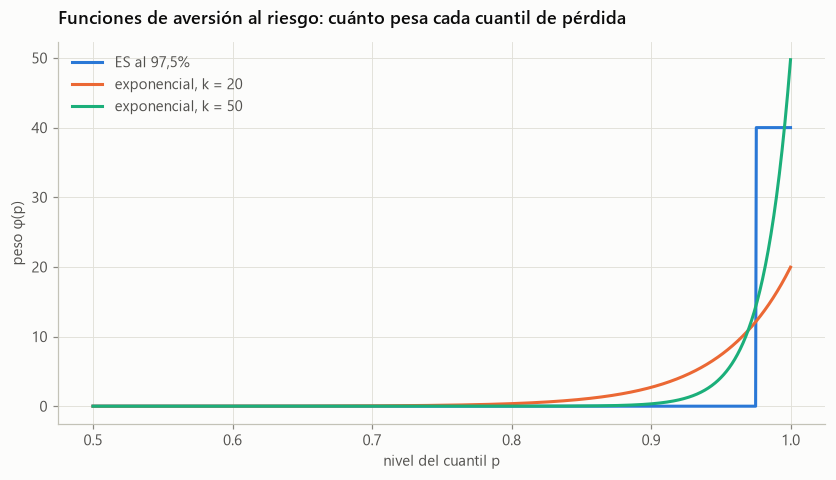

In [2]:
perdidas = -r_ipsa.to_numpy()
filas = {}
for nivel in (0.95, 0.975, 0.99):
    var_ = riesgo.var_historico(r_ipsa, nivel)
    es_ = riesgo.es_historico(r_ipsa, nivel)
    promedio_vars = np.mean([np.quantile(perdidas, u) for u in np.linspace(nivel, 1, 2_000, endpoint=False)])
    filas[f"{nivel:.1%}"] = {"VaR": var_, "ES": es_, "promedio de los VaR sobre el nivel": promedio_vars,
                             "ES normal": riesgo.es_normal(r_ipsa.mean(), r_ipsa.std(), nivel)}
tabla_medidas = pd.DataFrame(filas).T
espectrales = pd.Series({f"aversión k = {k}": fa.medida_espectral(perdidas, k) for k in (1, 5, 20, 50, 200)}, name="medida espectral")
print(tabla_medidas.map("{:.2%}".format).to_string())
print("\nMedidas espectrales exponenciales de la pérdida diaria:")
print(espectrales.map("{:.2%}".format).to_string())

p = np.linspace(0.5, 0.9999, 1_000)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(p, np.where(p >= 0.975, 1 / 0.025, 0), color=COLORES[0], linewidth=2, label="ES al 97,5%")
for color, k in zip(COLORES[1:], (20, 50)):
    ax.plot(p, k * np.exp(-k * (1 - p)) / (1 - np.exp(-k)), color=color, linewidth=2, label=f"exponencial, k = {k}")
ax.set_xlabel("nivel del cuantil p")
ax.set_ylabel("peso φ(p)")
ax.set_title("Funciones de aversión al riesgo: cuánto pesa cada cuantil de pérdida")
ax.legend(loc="upper left")
plt.show()

**Lectura.**

- **El ES supera al VaR en todos los niveles:** al 99%, 5,59% frente a 3,42%. Es el promedio de los VaR de la cola: al promediar 2.000 cuantiles se obtiene 5,47%, y la diferencia viene de la discretización.
- **La normal subestima la cola.** Su ES al 99% es 3,59%, frente a 5,59% en los datos: la cola del IPSA es mucho más gruesa de lo que sugiere su desviación estándar.
- **La aversión al riesgo elige cuánto de la cola mirar.** Las medidas espectrales van de 0,31% con aversión baja, que pondera casi por igual todos los días, a 6,49% con k = 200, más que el ES al 99%.

### Ejercicios resueltos

**Ejercicio 1.1. Expected shortfall desde las peores pérdidas** *(banco de ejercicios de frm-prep)*

Las cinco pérdidas más allá del VaR al 95%, en millones, son 8, 10, 12, 15 y 20. Calcula el expected shortfall.

In [3]:
cola = np.array([8, 10, 12, 15, 20])
print(f"Respuesta: ES = promedio de las pérdidas de la cola = {cola.mean():.0f} millones")

Respuesta: ES = promedio de las pérdidas de la cola = 13 millones


**Ejercicio 1.2. VaR, ES y medida espectral de una distribución discreta** *(ejercicio propio)*

Una cartera pierde 0 con probabilidad 90%, 10 con 6%, 30 con 3% y 100 con 1%. Calcula el VaR y el ES al 95% y al 99%, y una medida espectral exponencial con k = 20 usando 10.000 cuantiles.

In [4]:
valores_p = np.array([0, 10, 30, 100])
probs = np.array([0.90, 0.06, 0.03, 0.01])
cuantiles = np.repeat(valores_p, (probs * 10_000).astype(int))
for nivel in (0.95, 0.99):
    var_d = np.quantile(cuantiles, nivel, method="lower")
    es_d = cuantiles[int(nivel * 10_000):].mean()
    print(f"Nivel {nivel:.0%}: VaR = {var_d:.0f}; ES = {es_d:.1f}")
print(f"Respuesta: la medida espectral con k = 20 es {fa.medida_espectral(cuantiles, 20):.2f}: pondera toda la cola, con más peso en la pérdida de 100.")

Nivel 95%: VaR = 10; ES = 40.0
Nivel 99%: VaR = 30; ES = 100.0
Respuesta: la medida espectral con k = 20 es 32.35: pondera toda la cola, con más peso en la pérdida de 100.


**Ejercicio 1.3. La equivalencia de Basilea entre VaR y ES** *(ejercicio propio)*

Con pérdidas normales, compara el VaR al 99% con el ES al 97,5%, ambos en múltiplos de la desviación estándar. ¿Por qué Basilea eligió 97,5% para el ES?

In [5]:
var99 = stats.norm.ppf(0.99)
es975 = stats.norm.pdf(stats.norm.ppf(0.975)) / 0.025
print(f"VaR 99% = {var99:.3f}σ; ES 97,5% = φ(z)/(1 - 0,975) = {es975:.3f}σ")
print("Respuesta: con normalidad son casi iguales, así que el cambio de medida no alteró el capital de las carteras normales; con colas pesadas, el ES sube más.")

VaR 99% = 2.326σ; ES 97,5% = φ(z)/(1 - 0,975) = 2.338σ
Respuesta: con normalidad son casi iguales, así que el cambio de medida no alteró el capital de las carteras normales; con colas pesadas, el ES sube más.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Para una distribución de pérdidas normal, el VaR al 99% es \$2.33M (o sea la volatilidad en dólares es \$1M). Usando el multiplicador de ES de ~2.67 al 99%, el expected shortfall es más cercano a:

- **A.** $1.00M
- **B.** $2.33M
- **C.** $2.67M
- **D.** $3.00M

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Para la normal, $ES = \sigma \times \dfrac{\phi(z)}{1-c}$. Con $\sigma V = \$1\text{M}$ y el multiplicador al 99% $\approx 2.67$, $ES \approx 2.67 \times 1 = \$2.67\text{M}$, por encima del VaR de \$2.33M.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

¿Qué propiedad NO cumple en general el VaR, lo que le impide ser una medida de riesgo coherente?

- **A.** Monotonicidad.
- **B.** Subaditividad (el riesgo de una cartera combinada no debería superar la suma de los riesgos individuales).
- **C.** Homogeneidad positiva.
- **D.** Invarianza ante traslaciones.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** Una medida de riesgo coherente debe cumplir monotonicidad, invarianza ante traslaciones, homogeneidad positiva y subaditividad. El VaR puede violar la subaditividad (el VaR de una cartera fusionada puede superar la suma de las partes), por lo que no es coherente; el ES sí lo es.

</details>

### Trampas frecuentes

- El VaR no es coherente porque puede violar la subaditividad; el ES sí es coherente.
- El ES al 97,5% de una normal es casi igual al VaR al 99%: es la calibración de Basilea.
- Una medida espectral es coherente solo si su función de aversión es no decreciente.

## VRM-2. Cálculo y aplicación del VaR

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Métodos.** Simulación histórica (sin supuestos de distribución, pero solo con el pasado), con ponderación por antigüedad o por volatilidad (simulación histórica filtrada); delta-normal (rápido, lineal); Monte Carlo con revaluación completa.
- **No linealidad.** Para opciones, la aproximación delta-gamma $\Delta V \approx \delta\Delta S + \frac{1}{2}\gamma\Delta S^2$ agrega asimetría. Con ella, Cornish-Fisher corrige el cuantil normal: $z_{CF} = z + \frac{(z^2-1)S}{6} + \frac{(z^3 - 3z)K}{24} - \frac{(2z^3-5z)S^2}{36}$.
- **Descomposición.** VaR marginal: $\partial VaR/\partial x_i = z\,(\Sigma x)_i/\sigma_p$. VaR de componentes: $x_i \times$ marginal, que suma exactamente el VaR total (Euler). VaR incremental: el cambio del VaR al agregar o quitar una posición completa.
- **Horizonte.** Con retornos i.i.d., $VaR_T = VaR_1\sqrt{T}$. VaR en estrés: calibrado con un período de tensión.

### Análisis avanzado: VaR de componentes y VaR de una cartera con opciones

Primero se descompone el VaR al 99% de una cartera con $1.000 millones en cada acción del IPSA y USD 10 millones, con la matriz de covarianza diaria desde 2019. Luego, una mesa que vendió calls a un mes en el dinero sobre USD 50 millones calcula su VaR a un día con cuatro métodos: delta-normal, delta-gamma con Cornish-Fisher, Monte Carlo con revaluación completa y simulación histórica con revaluación completa usando los cambios diarios del dólar de los últimos dos años.

In [6]:
factores_diarios = pd.concat([retornos[acciones], dolar_alineado.pct_change().rename("Dólar")], axis=1, sort=True).loc[retornos.index].dropna()
posiciones = np.array([1_000.0] * len(acciones) + [10 * spot])
descomposicion = fa.descomposicion_var(posiciones, factores_diarios.cov().to_numpy(), 0.99, list(factores_diarios.columns))
var_total = descomposicion["var_componente"].sum()
sin_dolar = fa.descomposicion_var(posiciones[:-1], factores_diarios[acciones].cov().to_numpy(), 0.99)["var_componente"].sum()
print(f"VaR total {var_total:,.1f} millones; suma de VaR individuales {descomposicion['var_individual'].sum():,.1f};"
      f" VaR incremental de los dólares {var_total - sin_dolar:,.1f}")
print(descomposicion.round(3).to_string())

nominal_op, k_op, t_op = 50.0, spot, 1 / 12
precio_op = frm.black_scholes(spot, k_op, r_clp, vol_usd, t_op, q=r_usd)
g = frm.griegas(spot, k_op, r_clp, vol_usd, t_op, q=r_usd)
delta_pos, gamma_pos = -nominal_op * g["delta"], -nominal_op * g["gamma"]
sigma_s = spot * vol_usd / np.sqrt(252)
a_, b_ = delta_pos * sigma_s, 0.5 * gamma_pos * sigma_s**2
k2, k3, k4 = a_**2 + 2 * b_**2, 6 * a_**2 * b_ + 8 * b_**3, 48 * a_**2 * b_**2 + 48 * b_**4
var_dn = stats.norm.ppf(0.99) * abs(a_)
var_dg = fa.var_cornish_fisher(b_, np.sqrt(k2), k3 / k2**1.5, k4 / k2**2, 0.99)
rng = np.random.default_rng(2)
s_mc = spot * np.exp(-0.5 * (vol_usd**2) / 252 + vol_usd / np.sqrt(252) * rng.standard_normal(200_000))
valor_hoy = -nominal_op * precio_op
pnl_mc = -nominal_op * fa.black_scholes_vectorial(s_mc, k_op, r_clp, vol_usd, t_op - 1 / 252, q=r_usd) - valor_hoy
cambios_hist = np.log(dolar).diff().dropna().iloc[-504:].to_numpy()
pnl_hist = -nominal_op * fa.black_scholes_vectorial(spot * np.exp(cambios_hist), k_op, r_clp, vol_usd, t_op - 1 / 252, q=r_usd) - valor_hoy
tabla_opciones = pd.Series({"delta-normal": var_dn, "delta-gamma con Cornish-Fisher": var_dg,
                            "Monte Carlo con revaluación completa": -np.quantile(pnl_mc, 0.01),
                            "simulación histórica con revaluación completa": -np.quantile(pnl_hist, 0.01)},
                           name="VaR a un día al 99%, millones de pesos")
print(f"\nCalls vendidas: prima {precio_op:.2f} pesos por dólar; delta de la posición {delta_pos:.2f} millones de USD; gamma {gamma_pos:.4f}")
tabla_opciones.round(1).to_frame()

VaR total 313.6 millones; suma de VaR individuales 607.2; VaR incremental de los dólares 13.4
                 posicion  var_individual  var_marginal  var_componente  porcentaje
BCI            1,000.0000         43.3300        0.0260         26.2420      0.0840
Santander      1,000.0000         40.2820        0.0260         25.5940      0.0820
Banco de Chile 1,000.0000         39.5170        0.0240         23.8420      0.0760
Cencosud       1,000.0000         47.7320        0.0280         28.2480      0.0900
CMPC           1,000.0000         49.7050        0.0310         31.0290      0.0990
Copec          1,000.0000         46.3220        0.0290         29.2680      0.0930
Enel Chile     1,000.0000         45.3180        0.0240         23.8330      0.0760
Falabella      1,000.0000         49.4250        0.0280         27.8200      0.0890
SQM-B          1,000.0000         65.4490        0.0330         32.8140      0.1050
Dólar          9,593.9000        180.0820        0.0070         64

,"VaR a un día al 99%, millones de pesos"
delta-normal,378.8000
delta-gamma con Cornish-Fisher,454.4000
Monte Carlo con revaluación completa,442.1000
simulación histórica con revaluación completa,487.5000


**Lectura.**

- **La diversificación reduce el VaR a la mitad.** El VaR al 99% de la cartera es 314 millones, frente a 607 si se sumaran los VaR individuales.
- **El dólar es el mayor riesgo individual y un diversificador.** Su VaR individual es 180 millones, pero aporta solo 65 al total, 21%, y su VaR incremental es apenas 13 millones, por su correlación negativa con las acciones.
- **El delta-normal subestima el riesgo de las calls vendidas.** Da 379 millones; con la gamma negativa, Cornish-Fisher da 454 y la revaluación completa por Monte Carlo, 442. La simulación histórica con revaluación completa llega a 488, porque los cambios reales del dólar tienen colas más gruesas que la normal. El delta-normal queda entre 14% y 22% bajo las medidas que revalúan.

### Ejercicios resueltos

**Ejercicio 2.1. VaR paramétrico y raíz del tiempo** *(banco de ejercicios de frm-prep)*

Una cartera de $20 millones tiene volatilidad diaria de 1,5%. Con retornos normales y media cero, calcula el VaR al 99% a un día con z = 2,33. Otra posición tiene un VaR a un día de $1 millón: ¿cuál es su VaR a 10 días?

In [7]:
print(f"VaR = 2,33 × 1,5% × 20.000.000 = {2.33 * 0.015 * 20_000_000:,.0f}")
print(f"Respuesta: VaR a 10 días = 1.000.000 × raíz(10) = {1_000_000 * np.sqrt(10):,.0f}, si los retornos son independientes.")

VaR = 2,33 × 1,5% × 20.000.000 = 699,000
Respuesta: VaR a 10 días = 1.000.000 × raíz(10) = 3,162,278, si los retornos son independientes.


**Ejercicio 2.2. VaR diversificado y de componentes** *(banco de ejercicios de frm-prep)*

Dos posiciones tienen VaR individuales de $3 millones y $4 millones con correlación 0,5: ¿cuál es el VaR de la cartera? En otra cartera, los VaR de componentes son $6 millones y $4 millones: ¿cuál es el VaR total y qué fracción aporta la primera?

In [8]:
print(f"VaR diversificado = raíz(9 + 16 + 2·0,5·3·4) = {fa.agregar_riesgos([3, 4], [[1, 0.5], [0.5, 1]]):.2f} millones")
print("Respuesta: los VaR de componentes suman el total, 6 + 4 = 10 millones, y la primera aporta 60%.")

VaR diversificado = raíz(9 + 16 + 2·0,5·3·4) = 6.08 millones
Respuesta: los VaR de componentes suman el total, 6 + 4 = 10 millones, y la primera aporta 60%.


**Ejercicio 2.3. VaR por simulación histórica** *(banco de ejercicios de frm-prep)*

Con 100 observaciones diarias de resultados, ¿qué observación da el VaR al 95%? Aplícalo a los últimos 100 retornos del ETF IPSA sobre una posición de $1.000 millones.

In [9]:
ultimos = r_ipsa.iloc[-100:].sort_values()
print("Con 100 observaciones, el 5% de la cola son 5 días: el VaR es la quinta peor pérdida (o, según la convención, la sexta).")
print(f"Respuesta: las cinco peores son {(-ultimos.iloc[:5] * 1_000).round(1).tolist()} millones; VaR al 95% = {-ultimos.iloc[4] * 1_000:.1f} millones.")

Con 100 observaciones, el 5% de la cola son 5 días: el VaR es la quinta peor pérdida (o, según la convención, la sexta).
Respuesta: las cinco peores son [27.0, 24.4, 22.7, 16.8, 16.5] millones; VaR al 95% = 16.5 millones.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

El activo A tiene un VaR de \$4M y el activo B un VaR de \$3M, con una correlación de -0.5. El VaR de la cartera es más cercano a:

- **A.** $1.00M
- **B.** $5.00M
- **C.** $3.61M
- **D.** $7.00M

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** $\text{VaR}_p = \sqrt{16 + 9 + 2(-0.5)(4)(3)} = \sqrt{25 - 12} = \sqrt{13} \approx \$3.61\text{M}$. La correlación negativa da un gran beneficio de diversificación.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Los límites de riesgo basados en VaR pueden ser procíclicos porque:

- **A.** ignoran la volatilidad por completo.
- **B.** cuando la volatilidad sube en una crisis, el VaR medido salta, forzando a las firmas a recortar posiciones y vender en mercados en caída, amplificando la tensión.
- **C.** siempre reducen el riesgo en una recesión sin efectos secundarios.
- **D.** solo aplican en mercados calmos.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** Cuando la volatilidad y las correlaciones se disparan en el estrés, el VaR estimado sube, incumpliendo límites y forzando desapalancamiento. La venta simultánea de muchas firmas restringidas por VaR deprime aún más los precios — un bucle de retroalimentación que los reguladores intentan amortiguar con VaR estresado y colchones contracíclicos.

</details>

### Trampas frecuentes

- El delta-normal subestima el riesgo de una opción vendida, porque ignora la gamma negativa.
- El VaR de componentes suma el total; los VaR individuales, no.
- La raíz del tiempo supone retornos i.i.d. y una cartera constante durante el horizonte.

## VRM-3. Medición y monitoreo de la volatilidad

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Volatilidad cambiante.** Los retornos tienen colas pesadas en parte porque su varianza cambia en el tiempo; normalizados por una volatilidad condicional, se parecen más a una normal.
- **EWMA.** $\sigma_t^2 = \lambda\sigma_{t-1}^2 + (1-\lambda)r_{t-1}^2$; RiskMetrics usa λ = 0,94 para datos diarios. No tiene nivel de largo plazo.
- **GARCH(1,1).** $\sigma_t^2 = \omega + \alpha r_{t-1}^2 + \beta\sigma_{t-1}^2$, con varianza de largo plazo $V_L = \omega/(1 - \alpha - \beta)$ y persistencia α + β. El pronóstico revierte: $E[\sigma_{t+k}^2] = V_L + (\alpha + \beta)^k(\sigma_t^2 - V_L)$.
- **Estructura temporal.** La varianza promedio esperada hasta T, que es la que se usa para valorar una opción, es $V_L + \frac{1 - e^{-aT}}{aT}(\sigma_t^2 - V_L)$ con $a = \ln\frac{1}{\alpha+\beta}$.
- **Correlaciones.** Se actualizan igual que las varianzas, con EWMA o GARCH multivariado; la matriz resultante debe ser semidefinida positiva.

### Análisis avanzado: GARCH del dólar, estructura temporal y pronóstico fuera de muestra

Se estima un GARCH(1,1) con los retornos diarios del dólar de 2000 a 2015. Con esos parámetros fijos, sin volver a estimar, se filtra la volatilidad desde 2016 y se compara su pronóstico de la varianza de los 20 días siguientes con el de EWMA y el de la varianza del último año. Luego se calcula la estructura temporal de volatilidad de hoy.

ω = 0.0049, α = 0.076, β = 0.914; persistencia 0.9891; volatilidad de largo plazo 10.6% anual; vida media 63 días


                         error cuadrático medio  QLIKE  R² de Mincer-Zarnowitz
GARCH                                   85.9120 0.1640                  0.2360
EWMA                                    90.9810 0.1830                  0.2520
varianza del último año                 96.9960 0.2070                  0.1110


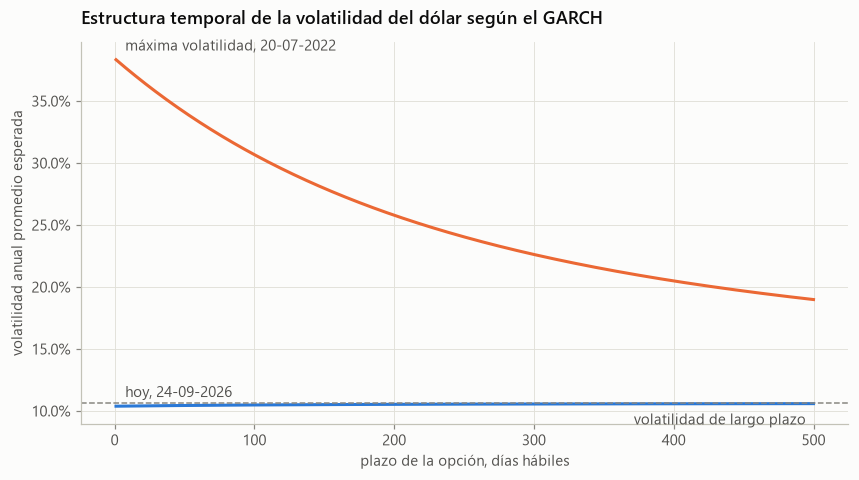

Volatilidad condicional hoy 10.4% anual; a 21 días 10.4%; a 252 días 10.6%
El 20-07-2022: 38.4% anual; a 21 días 36.5%; a 252 días 24.0%


In [10]:
r_usd_diario = 100 * np.log(dolar).diff().dropna()
modelo_garch = arch_model(r_usd_diario.loc[:"2015"], mean="Constant", vol="GARCH", p=1, q=1, dist="normal").fit(disp="off")
mu_g, omega, alfa, beta = modelo_garch.params[["mu", "omega", "alpha[1]", "beta[1]"]]
v_largo = omega / (1 - alfa - beta)
print(f"ω = {omega:.4f}, α = {alfa:.3f}, β = {beta:.3f}; persistencia {alfa + beta:.4f};"
      f" volatilidad de largo plazo {np.sqrt(v_largo * 252):.1f}% anual; vida media {np.log(0.5) / np.log(alfa + beta):.0f} días")

e = (r_usd_diario - mu_g).to_numpy()
var_garch = np.empty(len(e)); var_ewma = np.empty(len(e))
var_garch[0] = var_ewma[0] = e[:250].var()
for t in range(1, len(e)):
    var_garch[t] = omega + alfa * e[t - 1] ** 2 + beta * var_garch[t - 1]
    var_ewma[t] = 0.94 * var_ewma[t - 1] + 0.06 * e[t - 1] ** 2
indice = r_usd_diario.index
persistencia = alfa + beta
h = np.arange(20)
pron = pd.DataFrame({
    "GARCH": [np.sum(v_largo + persistencia**h * (v - v_largo)) for v in var_garch],
    "EWMA": 20 * var_ewma,
    "varianza del último año": 20 * pd.Series(e, index=indice).rolling(250).var().shift(1).to_numpy(),
}, index=indice)
realizada = pd.Series(e**2, index=indice)[::-1].rolling(20).sum()[::-1]  # días t a t + 19, pronosticados con datos hasta t - 1
evaluacion = pd.concat([pron, realizada.rename("realizada")], axis=1).loc["2016":].dropna()
filas = {}
for modelo in ("GARCH", "EWMA", "varianza del último año"):
    f_, y_ = evaluacion[modelo], evaluacion["realizada"]
    filas[modelo] = {"error cuadrático medio": np.mean((f_ - y_) ** 2), "QLIKE": np.mean(y_ / f_ - np.log(y_ / f_) - 1),
                     "R² de Mincer-Zarnowitz": sm.OLS(y_, sm.add_constant(f_)).fit().rsquared}
print(pd.DataFrame(filas).T.round(3).to_string())

v_hoy = var_garch[-1]
a_g = np.log(1 / persistencia)
plazos_dias = np.arange(1, 501)
promedio = v_largo + (1 - np.exp(-a_g * plazos_dias)) / (a_g * plazos_dias) * (v_hoy - v_largo)
i_max = int(np.argmax(var_garch))
promedio_max = v_largo + (1 - np.exp(-a_g * plazos_dias)) / (a_g * plazos_dias) * (var_garch[i_max] - v_largo)
fig, ax = plt.subplots(figsize=(9, 4.5))
for color, curva_v, etiqueta in [(COLORES[0], promedio, f"hoy, {indice[-1]:%d-%m-%Y}"),
                                 (COLORES[1], promedio_max, f"máxima volatilidad, {indice[i_max]:%d-%m-%Y}")]:
    ax.plot(plazos_dias, np.sqrt(curva_v * 252) / 100, color=color, linewidth=2)
    ax.annotate(etiqueta, (plazos_dias[0], np.sqrt(curva_v[0] * 252) / 100), xytext=(6, 6), textcoords="offset points",
                color=TINTA_SECUNDARIA)
ax.axhline(np.sqrt(v_largo * 252) / 100, color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.annotate("volatilidad de largo plazo", (500, np.sqrt(v_largo * 252) / 100), xytext=(-5, -14), textcoords="offset points", ha="right",
            color=TINTA_SECUNDARIA)
eje_porcentaje(ax, decimales=1)
ax.set_xlabel("plazo de la opción, días hábiles")
ax.set_ylabel("volatilidad anual promedio esperada")
ax.set_title("Estructura temporal de la volatilidad del dólar según el GARCH")
plt.show()
print(f"Volatilidad condicional hoy {np.sqrt(v_hoy * 252):.1f}% anual; a 21 días {np.sqrt(promedio[20] * 252):.1f}%; a 252 días {np.sqrt(promedio[251] * 252):.1f}%")
print(f"El {indice[i_max]:%d-%m-%Y}: {np.sqrt(var_garch[i_max] * 252):.1f}% anual; a 21 días {np.sqrt(promedio_max[20] * 252):.1f}%; a 252 días {np.sqrt(promedio_max[251] * 252):.1f}%")

**Lectura.**

- **La volatilidad del dólar es muy persistente.** Con α = 0,076 y β = 0,914, un shock pierde la mitad de su efecto en 63 días. La volatilidad de largo plazo es 10,6% anual.
- **Fuera de la muestra, desde 2016, el GARCH tiene el menor error cuadrático y el menor QLIKE.** EWMA queda cerca, con un R² de Mincer-Zarnowitz algo mayor, y la varianza del último año, la que reacciona más lento, es la peor en las tres medidas.
- **La estructura temporal importa en los momentos de estrés.** Hoy la volatilidad condicional, 10,4%, está casi en su nivel de largo plazo y la curva es plana. El 20 de julio de 2022 llegó a 38,4%: una opción a un mes debía valorarse con 36,5% y una a un año con 24,0%. Usar la volatilidad del día para todos los plazos habría sobrevalorado las opciones largas.

### Ejercicios resueltos

**Ejercicio 3.1. EWMA y GARCH** *(banco de ejercicios de frm-prep)*

Con EWMA y λ = 0,94, la volatilidad de ayer fue 1,0% y el retorno de ayer 2,0%: estima la de hoy. Un GARCH(1,1) tiene ω = 0,000002, α = 0,13 y β = 0,86; el retorno de ayer fue 2% y la volatilidad de ayer 1,5%: pronostica la de hoy.

In [11]:
ewma = np.sqrt(0.94 * 0.01**2 + 0.06 * 0.02**2)
garch = np.sqrt(0.000002 + 0.13 * 0.02**2 + 0.86 * 0.015**2)
print(f"EWMA: raíz(0,94·0,01² + 0,06·0,02²) = {ewma:.2%}")
print(f"Respuesta: GARCH: raíz(0,000002 + 0,13·0,02² + 0,86·0,015²) = {garch:.2%}")

EWMA: raíz(0,94·0,01² + 0,06·0,02²) = 1.09%
Respuesta: GARCH: raíz(0,000002 + 0,13·0,02² + 0,86·0,015²) = 1.57%


**Ejercicio 3.2. Reversión a la media y volatilidad para valorar una opción** *(ejercicio propio)*

Con el GARCH del ejercicio anterior, calcula la volatilidad diaria de largo plazo, el pronóstico de la varianza en 10 días y la volatilidad anual que debería usarse para una opción a 20 días, partiendo de una varianza diaria de 0,000250.

In [12]:
w_, a1, b1, v0 = 0.000002, 0.13, 0.86, 0.000250
vl = w_ / (1 - a1 - b1)
en_10 = vl + (a1 + b1) ** 10 * (v0 - vl)
a_ = np.log(1 / (a1 + b1))
prom_20 = vl + (1 - np.exp(-a_ * 20)) / (a_ * 20) * (v0 - vl)
print(f"V_L = 0,000002 / 0,01 = {vl:.6f}: volatilidad de largo plazo {np.sqrt(vl):.2%} diaria")
print(f"E[σ² en 10 días] = {en_10:.6f}")
print(f"Respuesta: volatilidad promedio para 20 días = {np.sqrt(prom_20 * 252):.2%} anual, entre la actual ({np.sqrt(v0 * 252):.2%}) y la de largo plazo ({np.sqrt(vl * 252):.2%}).")

V_L = 0,000002 / 0,01 = 0.000200: volatilidad de largo plazo 1.41% diaria
E[σ² en 10 días] = 0.000245
Respuesta: volatilidad promedio para 20 días = 24.86% anual, entre la actual (25.10%) y la de largo plazo (22.45%).


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Un modelo GARCH(1,1) es estimado con los parámetros: $\omega = 0.000002$, $\alpha = 0.12$, $\beta = 0.85$. La varianza condicional de ayer fue $\sigma^2_{t-1} = 0.0004$ (desviación estándar diaria = 2%) y el retorno de ayer fue $r_{t-1} = -0.03$ (-3%). ¿Cuál es la varianza condicional pronosticada para hoy y la varianza incondicional (de largo plazo)?

- **A.** Varianza de hoy = 0.000450; Varianza incondicional = 0.000067
- **B.** Varianza de hoy = $0.000002 + 0.12 \times (-0.03)^2 + 0.85 \times 0.0004 = 0.000002 + 0.000108 + 0.000340 = 0.000450$; Varianza incondicional = $\omega/(1-\alpha-\beta) = 0.000002/(1-0.12-0.85) = 0.000067$
- **C.** Varianza de hoy = 0.000450; Varianza incondicional no existe porque α + β = 0.97 ≥ 1, lo que indica un proceso integrado.
- **D.** Varianza de hoy = 0.000340; Varianza incondicional = el modelo GARCH(1,1) no tiene varianza incondicional finita porque α + β = 0.97 > 0.5.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** **Fórmula GARCH(1,1):**
$$\sigma^2_t = \omega + \alpha \cdot r^2_{t-1} + \beta \cdot \sigma^2_{t-1}$$

**Cálculo de la varianza de hoy:**
$$\sigma^2_t = 0.000002 + 0.12 \times (-0.03)^2 + 0.85 \times 0.0004$$
$$= 0.000002 + 0.12 \times 0.0009 + 0.000340$$
$$= 0.000002 + 0.000108 + 0.000340 = \mathbf{0.000450}$$

Desviación estándar hoy: $\sqrt{0.000450} \approx 2.12\%$

**Varianza incondicional (largo plazo):**
$$\bar{\sigma}^2 = \frac{\omega}{1 - \alpha - \beta} = \frac{0.000002}{1 - 0.12 - 0.85} = \frac{0.000002}{0.03} \approx \mathbf{0.0000667}$$

Desviación estándar de largo plazo: $\sqrt{0.0000667} \approx 0.82\%$ diaria.

**Persistencia:** $\alpha + \beta = 0.97 < 1$, por lo que el proceso es covarianza-estacionario y la varianza incondicional es finita.

**Por qué los distractores son incorrectos:**
- **C**: El criterio de estacionariedad es $\alpha + \beta < 1$, no $< 0.5$.
- **D**: $\alpha + \beta = 0.97 < 1$, por lo que el proceso NO es integrado (IGARCH requeriría exactamente = 1).

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Una característica clave de un modelo GARCH(1,1) que EWMA no tiene es que GARCH:

- **A.** no puede estimarse con datos.
- **B.** incorpora reversión a la media hacia una varianza promedio de largo plazo, mientras que EWMA no tiene un nivel de largo plazo.
- **C.** ignora por completo los retornos recientes.
- **D.** supone volatilidad constante.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** EWMA es un caso especial de GARCH sin término constante, por lo que su pronóstico no tiene media de largo plazo. GARCH(1,1) agrega un peso sobre una varianza de largo plazo, produciendo reversión a la media: los pronósticos de volatilidad vuelven al nivel de largo plazo con el tiempo.

</details>

### Trampas frecuentes

- EWMA es un GARCH sin ω y con α + β = 1: no tiene volatilidad de largo plazo.
- Un GARCH solo es estacionario si α + β < 1; cuanto más cerca de 1, más lenta la reversión.
- Para valorar una opción se usa la varianza promedio esperada hasta el vencimiento, no la de hoy.

## VRM-4. Calificaciones de crédito externas e internas

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Escalas.** Grado de inversión desde AAA hasta BBB− (Baa3); especulativo desde BB+ (Ba1). Las perspectivas y las revisiones anticipan cambios.
- **A lo largo del ciclo y puntual.** Las agencias califican a lo largo del ciclo (through-the-cycle, TTC): calificaciones estables que no reaccionan a cada fase. Las PD puntuales (point-in-time, PIT) se mueven con la economía. Con el modelo de un factor, $PD_{PIT} = N\left(\frac{N^{-1}(PD_{TTC}) - \sqrt{\rho}\,M_t}{\sqrt{1-\rho}}\right)$.
- **Matrices de transición.** Con el supuesto de Markov, la matriz a n años es la de un año elevada a n. La PD acumulada a n años es $1 - \prod(1 - h_i)$; la marginal de un año es la acumulada de ese año menos la del anterior.
- **Calificaciones internas.** Modelos de puntaje como el Z de Altman, la regresión logística y modelos estructurales. Deben validarse por discriminación y calibración.
- **Comportamiento.** Las bajas tienden a seguir bajando (momentum) y las calificaciones reaccionan con rezago a la información de mercado.

### Análisis avanzado: PD a lo largo del ciclo frente a PD puntual con el IMACEC

El factor sistemático del modelo de Vasicek se aproxima con el crecimiento anual del IMACEC estandarizado, acotado entre −3 y 3. Con una correlación de 0,12 se calculan las PD puntuales mensuales de tres calificaciones con PD a lo largo del ciclo de 0,2%, 1% y 4%.

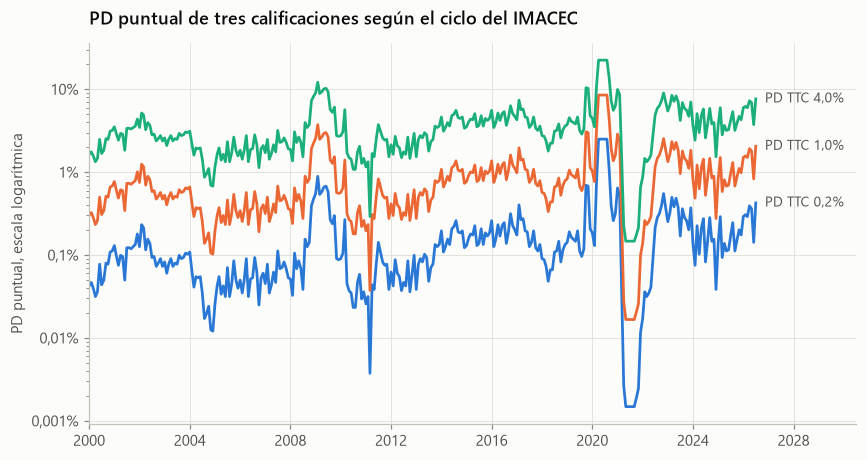

,mínima,fecha mínima,máxima,fecha máxima,última
"PD TTC 0,2%",0.001%,05-2021,2.50%,04-2020,0.42%
"PD TTC 1,0%",0.017%,05-2021,8.50%,04-2020,2.05%
"PD TTC 4,0%",0.147%,05-2021,22.41%,04-2020,7.63%


In [13]:
crecimiento = imacec.loc["2000":]
factor = ((crecimiento - crecimiento.mean()) / crecimiento.std()).clip(-3, 3)
rho_ciclo = 0.12
pd_pit = pd.DataFrame({f"PD TTC {p:.1%}".replace(".", ","): fa.pd_condicional_vasicek(p, rho_ciclo, factor.to_numpy())
                       for p in (0.002, 0.01, 0.04)}, index=factor.index)
fig, ax = plt.subplots(figsize=(9, 4.5))
for color, columna in zip(COLORES, pd_pit.columns):
    ax.semilogy(pd_pit.index, pd_pit[columna], color=color, linewidth=1.8)
    ax.annotate(columna, (pd_pit.index[-1], pd_pit[columna].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center",
                color=TINTA_SECUNDARIA, fontsize=9)
ax.set_xlim(pd_pit.index[0], pd_pit.index[-1] + pd.DateOffset(years=4))
from matplotlib.ticker import FuncFormatter
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{100 * v:g}%".replace(".", ",")))
ax.set_ylabel("PD puntual, escala logarítmica")
ax.set_title("PD puntual de tres calificaciones según el ciclo del IMACEC")
plt.show()
resumen_pit = pd.DataFrame({"mínima": pd_pit.min().map("{:.3%}".format), "fecha mínima": pd_pit.idxmin().dt.strftime("%m-%Y"),
                            "máxima": pd_pit.max().map("{:.2%}".format), "fecha máxima": pd_pit.idxmax().dt.strftime("%m-%Y"),
                            "última": pd_pit.iloc[-1].map("{:.2%}".format)})
resumen_pit

**Lectura.**

- **La misma calificación implica PD muy distintas según el ciclo.** Un emisor con PD de 1% a lo largo del ciclo tiene una PD puntual de 8,5% en la caída de abril de 2020 y de 0,02% en el rebote de mayo de 2021.
- **La PD puntual se mueve en órdenes de magnitud; la de las agencias casi no se mueve.** Para el capital, Basilea pide PD que reflejen el ciclo completo, para no amplificarlo. La contabilidad IFRS 9 pide, en cambio, PD puntuales y prospectivas para las provisiones.
- **El factor y la correlación son supuestos ilustrativos:** el IMACEC estandarizado y una correlación de 0,12.

### Ejercicios resueltos

**Ejercicio 4.1. PD acumulada y marginal** *(banco de ejercicios de frm-prep)*

Una contraparte tiene una PD anual constante de 3%. Calcula la PD acumulada a 2 años. Luego, un bono tiene PD condicional de 2% el primer año y 3% el segundo: calcula su PD acumulada y la marginal del segundo año.

In [14]:
print(f"PD acumulada constante a 2 años = 1 - 0,97² = {float(fa.pd_acumulada_constante(0.03, 2)):.2%}")
acumuladas = np.array([0.02, 1 - 0.98 * 0.97])
print(f"Respuesta: acumulada = 1 - 0,98·0,97 = {acumuladas[1]:.2%}; marginal del año 2 = {fa.pd_marginal(acumuladas)[1]:.2%} = 0,98 × 3%.")

PD acumulada constante a 2 años = 1 - 0,97² = 5.91%
Respuesta: acumulada = 1 - 0,98·0,97 = 4.94%; marginal del año 2 = 2.94% = 0,98 × 3%.


**Ejercicio 4.2. Matriz de transición a varios años** *(ejercicio propio)*

Con la matriz anual de abajo, para emisores A, B, C y en incumplimiento (D, absorbente), calcula la PD acumulada a 1, 3 y 5 años de cada calificación.

In [15]:
matriz = pd.DataFrame([[0.92, 0.07, 0.008, 0.002], [0.05, 0.85, 0.08, 0.02], [0.01, 0.09, 0.80, 0.10], [0, 0, 0, 1]],
                      index=list("ABCD"), columns=list("ABCD"))
pd_acum = pd.DataFrame({f"{n} años": frm.transicion_multiperiodo(matriz, n)["D"].iloc[:3] for n in (1, 3, 5)})
print(pd_acum.map("{:.2%}".format).to_string())
print("Respuesta: la PD a 5 años de A es mucho más que 5 veces la de un año, porque los emisores A pueden bajar primero a B o C.")

   1 años  3 años  5 años
A   0.20%   1.22%   3.03%
B   2.00%   7.32%  13.29%
C  10.00%  24.96%  35.45%
Respuesta: la PD a 5 años de A es mucho más que 5 veces la de un año, porque los emisores A pueden bajar primero a B o C.


**Ejercicio 4.3. Z de Altman** *(ejercicio propio)*

Una manufacturera tiene activos de 1.000, pasivos de 600, capital de trabajo de 120, utilidades retenidas de 200, EBIT de 90, patrimonio bursátil de 500 y ventas de 1.100. Calcula su Z y clasifícala.

In [16]:
z_ = fa.z_altman(120, 200, 90, 500, 1_100, 1_000, 600)
zona = "segura" if z_ > 2.99 else ("gris" if z_ > 1.81 else "de peligro")
print(f"Respuesta: Z = 1,2·0,12 + 1,4·0,20 + 3,3·0,09 + 0,6·0,833 + 1,0·1,10 = {z_:.2f}: zona {zona}.")

Respuesta: Z = 1,2·0,12 + 1,4·0,20 + 3,3·0,09 + 0,6·0,833 + 1,0·1,10 = 2.32: zona gris.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Un bono tiene una probabilidad de default del año 1 de 2% y, condicional a sobrevivir, del año 2 de 3%. Su probabilidad de default acumulada a 2 años es más cercana a:

- **A.** 6.00%
- **B.** 4.94%
- **C.** 5.00%
- **D.** 2.94%

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** PD acumulada $= 1 - (1 - 0.02)(1 - 0.03) = 1 - 0.98 \times 0.97 = 1 - 0.9506 = 4.94\%$.

</details>

**Pregunta 2** *(banco de frm-prep, cálculo, dificultad avanzada)*

Un bono sobrevive los años 1 y 2 con probabilidades que implican una supervivencia acumulada de 95.06% al final del año 2. Si la probabilidad de default condicional del año 3 es 4%, la probabilidad de default marginal (incondicional) del año 3 es más cercana a:

- **A.** 4.00%
- **B.** 0.04%
- **C.** 5.94%
- **D.** 3.80%

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** PD marginal$_3$ = (supervivencia al final del año 2) × (PD condicional$_3$) = $0.9506 \times 0.04 = 3.80\%$.

</details>

### Trampas frecuentes

- La PD marginal de un año es incondicional; la condicional se divide por la supervivencia previa.
- Las calificaciones de agencias son a lo largo del ciclo: no reflejan cada cambio de la economía.
- Elevar la matriz a n supone que las transiciones no dependen de la historia, lo que ignora el momentum de las bajas.

## VRM-5. Riesgo país: determinantes, medidas e implicancias

*Relevancia en el examen: media. Dificultad: intermedia.*

### Idea central

- **Fuentes.** Crecimiento y su estabilidad, inflación, cuentas externas, dependencia de materias primas, instituciones, riesgo político, sistema legal y estabilidad del sistema financiero.
- **Riesgo soberano.** Depende de la capacidad y de la voluntad de pago. La deuda en moneda local rara vez entra en incumplimiento formal, porque se puede inflar; la deuda en moneda extranjera sí.
- **Medidas.** Calificaciones soberanas, spreads de bonos en dólares sobre el Tesoro de EE.UU. (como el EMBI) y CDS soberanos. Del spread se obtiene una intensidad de incumplimiento, igual que en una empresa.
- **Contagio y techo soberano.** Las crisis se transmiten entre países, y la calificación de una empresa rara vez supera la de su país.
- **Prima de riesgo país.** En valoración se suma al costo de capital, por ejemplo con el spread soberano ajustado por la volatilidad relativa de acciones y bonos.

### Análisis avanzado: un tablero macroeconómico de riesgo para Chile

Se arma un índice simple con cinco variables mensuales estandarizadas, con signo tal que más alto significa más riesgo: crecimiento del IMACEC (con signo negativo), inflación de 12 meses, depreciación del peso en 12 meses, variación del cobre en 12 meses (con signo negativo) y la TPM. Es un índice ilustrativo, no una calificación: muestra cómo se combinan determinantes distintos.

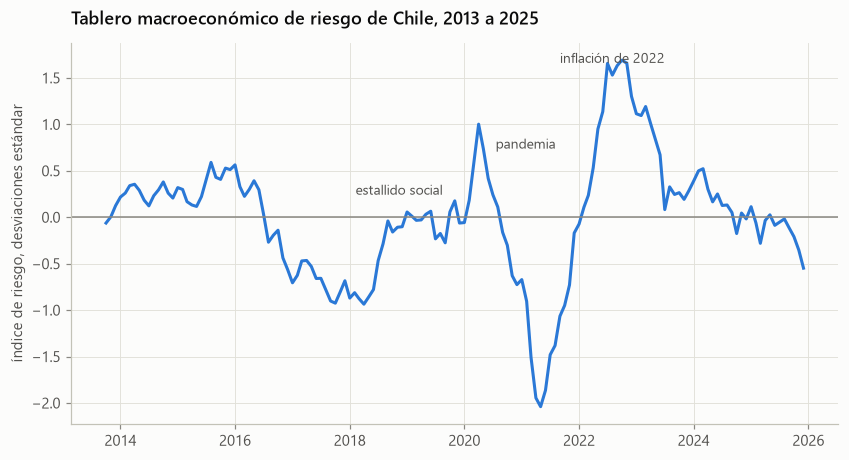

Máximo del índice: 1.69 en 10-2022. Contribuciones ese mes:
crecimiento del IMACEC           0.1300
inflación 12 meses               0.5800
depreciación del peso 12 meses   0.2300
variación del cobre 12 meses     0.2700
TPM                              0.4700


,crecimiento del IMACEC,inflación 12 meses,depreciación del peso 12 meses,variación del cobre 12 meses,TPM
fecha,,,,,
2022-10-01,-1.2000,12.8900,16.0700,-24.3900,11.0500
2025-12-01,1.7000,3.4400,-6.9700,26.5300,4.6300


In [17]:
mensual = pd.concat({
    "crecimiento del IMACEC": imacec,
    "inflación 12 meses": ((1 + ipc / 100).rolling(12).apply(np.prod, raw=True) - 1) * 100,
    "depreciación del peso 12 meses": np.log(dolar.resample("MS").mean()).diff(12) * 100,
    "variación del cobre 12 meses": np.log(cobre.resample("MS").mean()).diff(12) * 100,
    "TPM": tpm.resample("MS").mean() * 100,
}, axis=1, sort=True).loc["2013":"2025"].dropna()
signos = {"crecimiento del IMACEC": -1, "inflación 12 meses": 1, "depreciación del peso 12 meses": 1,
          "variación del cobre 12 meses": -1, "TPM": 1}
z_scores = (mensual - mensual.mean()) / mensual.std()
indice_riesgo = sum(signos[c] * z_scores[c] for c in mensual.columns) / len(mensual.columns)
episodios = {"estallido social": "2019-11", "pandemia": "2020-05", "inflación de 2022": "2022-08"}
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(indice_riesgo.index, indice_riesgo, color=COLORES[0], linewidth=2)
ax.axhline(0, color=TINTA_TENUE, linewidth=1)
desplazamientos_e = {"estallido social": (-8, 4, "right"), "pandemia": (8, 0, "left"), "inflación de 2022": (0, 8, "center")}
for etiqueta, fecha in episodios.items():
    valor = indice_riesgo.loc[fecha].iloc[0]
    dx, dy, alineacion = desplazamientos_e[etiqueta]
    ax.annotate(etiqueta, (pd.Timestamp(fecha), valor), xytext=(dx, dy), textcoords="offset points", ha=alineacion,
                color=TINTA_SECUNDARIA, fontsize=9)
ax.set_ylabel("índice de riesgo, desviaciones estándar")
ax.set_title("Tablero macroeconómico de riesgo de Chile, 2013 a 2025")
plt.show()
maximo = indice_riesgo.idxmax()
print(f"Máximo del índice: {indice_riesgo.max():.2f} en {maximo:%m-%Y}. Contribuciones ese mes:")
print((pd.Series(signos) * z_scores.loc[maximo] / len(signos)).round(2).to_string())
mensual.loc[[maximo, mensual.index[-1]]].round(2)

**Lectura.**

- **El mayor riesgo del período fue octubre de 2022:** inflación de 12,9%, TPM sobre 11%, depreciación del peso de 16% en un año y caída del cobre de 24%. La inflación y la TPM explican más de 60% del índice ese mes.
- **La pandemia aparece como un salto breve y el estallido social casi no se ve.** Sus efectos financieros fueron rápidos y pasaron sobre todo por el peso, mientras el índice promedia variables mensuales que se mueven lento.
- **A fines de 2025 el índice está bajo su promedio,** con inflación de 3,4%, el cobre al alza y el peso apreciado. Un índice así orienta, pero no reemplaza a las calificaciones ni a los spreads de mercado.

### Ejercicios resueltos

**Ejercicio 5.1. Probabilidad de incumplimiento soberano desde el spread** *(ejercicio propio)*

Un soberano emergente paga 350 puntos base sobre el Tesoro en sus bonos en dólares a 5 años. Con una recuperación de 25%, ¿qué intensidad de incumplimiento y qué probabilidad acumulada a 5 años implica?

In [18]:
lam = fa.intensidad_desde_spread(0.035, 0.25)
print(f"λ = 3,5% / 75% = {lam:.2%} anual")
print(f"Respuesta: PD a 5 años = 1 - e^(-{lam:.4f}·5) = {1 - np.exp(-lam * 5):.1%}, una probabilidad neutral al riesgo que incluye primas.")

λ = 3,5% / 75% = 4.67% anual
Respuesta: PD a 5 años = 1 - e^(-0.0467·5) = 20.8%, una probabilidad neutral al riesgo que incluye primas.


**Ejercicio 5.2. Prima de riesgo país en el costo de capital** *(ejercicio propio)*

El spread soberano de un país es 2%. La volatilidad de su mercado accionario es 24% y la de sus bonos soberanos en dólares, 12%. Con el método de Damodaran, ¿qué prima de riesgo país se suma al costo de capital de una empresa con exposición promedio al país?

In [19]:
prima = 0.02 * 0.24 / 0.12
print(f"Respuesta: prima de riesgo país = 2% × 24% / 12% = {prima:.0%}: las acciones son más volátiles que los bonos, así que la prima se escala.")

Respuesta: prima de riesgo país = 2% × 24% / 12% = 4%: las acciones son más volátiles que los bonos, así que la prima se escala.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

Una empresa multinacional evalúa invertir en un país emergente. El spread soberano del país sobre los bonos del Tesoro de EE.UU. es 350 puntos básicos. ¿Cuál de los siguientes componentes del riesgo país está capturado MEJOR por el spread soberano, y cuál componente importante queda tipicamente FUERA de esta medida?

- **A.** El spread soberano captura mejor el riesgo cambiario; el riesgo de crédito soberano queda fuera porque los gobiernos nunca incumplen en moneda local.
- **B.** El spread soberano captura mejor el riesgo de crédito soberano (probabilidad de incumplimiento del gobierno); el riesgo político (expropiación, cambio de régimen, violencia) queda tipicamente fuera o subestimado.
- **C.** El spread soberano captura todos los componentes del riesgo país incluyendo el riesgo político, el riesgo de transferencia y el riesgo cambiario.
- **D.** El spread soberano captura mejor el riesgo político; el riesgo de transferencia y convertibilidad queda fuera.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** El **spread soberano** (diferencial entre el rendimiento de un bono soberano en moneda extranjera y el bono libre de riesgo equivalente) refleja principalmente la **probabilidad de incumplimiento del gobierno** en sus obligaciones en moneda extranjera — es decir, el riesgo de crédito soberano. Componentes del riesgo país NO capturados completamente por el spread: (1) **Riesgo político:** Expropiación, cambios de política, inestabilidad gubernamental, violencia, que pueden materializarse sin que el soberano incumpla. (2) **Riesgo de transferencia:** Restricciones al repatriamiento de capital o dividendos (controles de capital). (3) **Riesgo de convertibilidad:** Imposibilidad de convertir moneda local a divisas extranjeras. Estos pueden afectar a empresas privadas incluso cuando el gobierno cumple con sus obligaciones de deuda. La opción D es incorrecta — el spread captura el riesgo de crédito, no principalmente el político. La opción C exagera lo que cubre el spread. La opción A es incorrecta — los gobiernos SÍ incumplen incluso en moneda local (ej. Argentina 2001).

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

El riesgo soberano difiere del riesgo de crédito corporativo ordinario principalmente porque un gobierno en default:

- **A.** puede ser forzado a la quiebra como una empresa.
- **B.** no tiene efecto sobre las firmas domésticas.
- **C.** puede ser incapaz o no estar dispuesto a pagar, y el recurso legal contra un soberano es limitado, haciendo centrales la voluntad de pago y los factores políticos.
- **D.** siempre tiene probabilidad de default cero.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** El riesgo soberano incluye tanto la capacidad como la voluntad de pago. Los acreedores tienen capacidad limitada para embargar activos o hacer valer reclamos entre fronteras, por lo que dominan los factores políticos y macro. La tensión soberana también eleva el riesgo de las firmas domésticas (efecto techo).

</details>

### Trampas frecuentes

- El spread soberano mide sobre todo riesgo de crédito; el riesgo político puede quedar subestimado.
- Un soberano puede incumplir en moneda extranjera aunque nunca lo haga en su propia moneda.
- Las probabilidades implícitas en spreads soberanos son neutrales al riesgo, como las corporativas.

## VRM-6. Medición del riesgo de crédito

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Pérdida esperada e inesperada.** $EL = PD \cdot LGD \cdot EAD$. Para un préstamo, $UL = EAD \cdot LGD\sqrt{PD(1-PD)}$ si la LGD es fija. Para una cartera, la UL depende de las correlaciones y no es la suma de las individuales.
- **Capital económico.** El VaR de crédito, típicamente al 99,9%, menos la pérdida esperada.
- **Modelo de Vasicek.** Con un factor común y correlación ρ, la tasa de incumplimiento en el peor caso es $WCDR = N\left(\frac{N^{-1}(PD) + \sqrt\rho N^{-1}(0,999)}{\sqrt{1-\rho}}\right)$.
- **IRB de Basilea.** $K = LGD\,[WCDR - PD] \times \frac{1 + (M - 2,5)b}{1 - 1,5b}$, con $b = (0,11852 - 0,05478\ln PD)^2$ y correlación entre 12% y 24% que baja con la PD. Los activos ponderados son $12,5 \times K \times EAD$.
- **Granularidad.** La fórmula supone una cartera infinitamente diversificada; una cartera concentrada necesita más capital.
- **Modelo de Merton.** El patrimonio es una call sobre los activos con strike igual a la deuda. La distancia al incumplimiento es $\frac{\ln(V/D) + (\mu - \sigma_V^2/2)T}{\sigma_V\sqrt T}$ y la PD, su normal acumulada con signo negativo.
- **Riesgo de contraparte en derivados.** Exposición esperada, exposición potencial futura y el ajuste por valoración de crédito (CVA).

### Análisis avanzado: capital IRB, granularidad y el modelo de Vasicek

Primero se grafica la ponderación de riesgo del método IRB para empresas según la PD, con LGD de 45% y vencimiento de 2,5 años. Luego se simulan carteras de 20 a 10.000 créditos con PD de 1% y la correlación de Basilea, y se compara su capital al 99,9% con el de la fórmula asintótica.

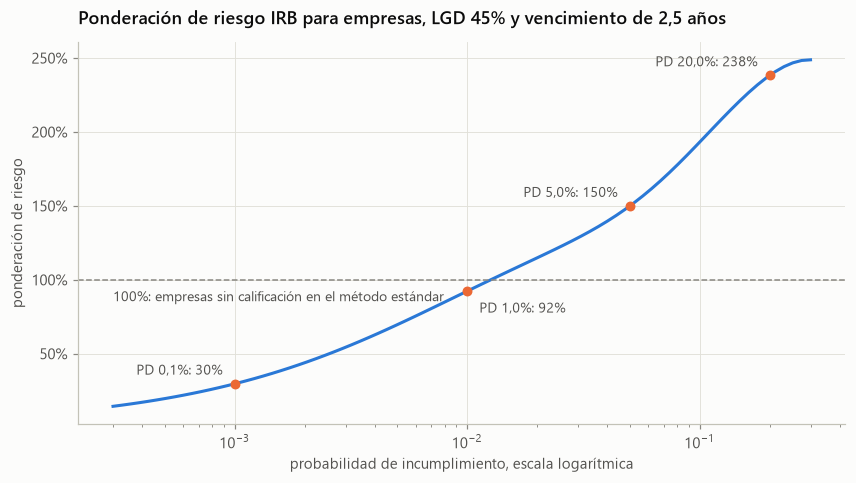

Correlación de Basilea para PD 1%: 0.193. Capital asintótico sin ajuste de vencimiento: 5.86%


,pérdida esperada,"VaR 99,9%",capital,capital / asintótico
20 créditos,0.0045,0.0900,0.0855,1.4580
100 créditos,0.0045,0.0720,0.0675,1.1516
1.000 créditos,0.0045,0.0639,0.0594,1.0132
10.000 créditos,0.0045,0.0620,0.0575,0.9809


In [20]:
pds = np.logspace(np.log10(0.0003), np.log10(0.30), 80)
ponderaciones = np.array([fa.capital_irb(p, 0.45)["ponderacion"] for p in pds])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogx(pds, ponderaciones, color=COLORES[0], linewidth=2)
ax.axhline(1.0, color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.annotate("100%: empresas sin calificación en el método estándar", (0.0003, 1.0), xytext=(0, -14), textcoords="offset points",
            color=TINTA_SECUNDARIA, fontsize=9)
for p_ref, (dx, dy, alineacion) in {0.001: (-8, 6, "right"), 0.01: (8, -14, "left"), 0.05: (-8, 6, "right"), 0.20: (-8, 6, "right")}.items():
    rw = fa.capital_irb(p_ref, 0.45)["ponderacion"]
    ax.scatter(p_ref, rw, color=COLORES[1], s=30, zorder=3)
    ax.annotate(f"PD {p_ref:.1%}: {rw:.0%}".replace(".", ","), (p_ref, rw), xytext=(dx, dy), textcoords="offset points", ha=alineacion,
                color=TINTA_SECUNDARIA, fontsize=9)
eje_porcentaje(ax)
ax.set_xlabel("probabilidad de incumplimiento, escala logarítmica")
ax.set_ylabel("ponderación de riesgo")
ax.set_title("Ponderación de riesgo IRB para empresas, LGD 45% y vencimiento de 2,5 años")
plt.show()

pd_g, lgd_g = 0.01, 0.45
rho_g = float(fa.correlacion_irb(pd_g))
asintotico = lgd_g * (frm.tasa_default_peor_caso(pd_g, rho_g) - pd_g)
filas = {}
for n in (20, 100, 1_000, 10_000):
    perdidas_c = fa.perdidas_copula_gaussiana(pd_g, rho_g, n, simulaciones=200_000, lgd=lgd_g, semilla=n)
    capital_n = np.quantile(perdidas_c, 0.999) - perdidas_c.mean()
    filas[f"{n:,} créditos".replace(",", ".")] = {"pérdida esperada": perdidas_c.mean(), "VaR 99,9%": np.quantile(perdidas_c, 0.999),
                                                  "capital": capital_n, "capital / asintótico": capital_n / asintotico}
print(f"Correlación de Basilea para PD 1%: {rho_g:.3f}. Capital asintótico sin ajuste de vencimiento: {asintotico:.2%}")
pd.DataFrame(filas).T.round(4)

**Lectura.**

- **La ponderación IRB crece con la PD, pero no en proporción.** Va de 30% con PD de 0,1% a 238% con PD de 20%, y cruza el 100% del método estándar algo sobre una PD de 1%. Para los buenos deudores, el IRB exige mucho menos capital.
- **La concentración importa.** Con PD de 1% y la correlación de Basilea de 0,19, una cartera de 20 créditos necesita 46% más capital que la fórmula asintótica, y una de 100, 15% más. Desde 1.000 créditos la fórmula es exacta. Basilea supone carteras granulares y deja la concentración al Pilar 2.

### Ejercicios resueltos

**Ejercicio 6.1. Pérdida esperada y capital económico** *(banco de ejercicios de frm-prep)*

Un préstamo tiene PD de 1,5%, LGD de 45% y exposición de $8 millones: calcula la pérdida esperada. Una cartera tiene un VaR de crédito al 99,9% de $5 millones y pérdida esperada de $0,8 millones: calcula el capital económico.

In [21]:
print(f"EL = 1,5% × 45% × 8.000.000 = {frm.perdida_esperada(0.015, 0.45, 8_000_000):,.0f}")
print("Respuesta: capital económico = VaR de crédito - EL = 5,0 - 0,8 = 4,2 millones.")

EL = 1,5% × 45% × 8.000.000 = 54,000
Respuesta: capital económico = VaR de crédito - EL = 5,0 - 0,8 = 4,2 millones.


**Ejercicio 6.2. Capital IRB de un préstamo** *(ejercicio propio)*

Un préstamo a una empresa de $10 millones tiene PD de 2%, LGD de 40% y vencimiento de 3 años. Calcula la correlación, el requerimiento K, los activos ponderados y el capital al 8%.

In [22]:
irb = fa.capital_irb(0.02, 0.40, vencimiento=3.0)
print({k: round(v, 4) for k, v in irb.items()})
print(f"Respuesta: APR = 12,5 × {irb['capital']:.4f} × 10.000.000 = {12.5 * irb['capital'] * 10_000_000:,.0f}; capital = 8% de los APR = {irb['capital'] * 10_000_000:,.0f}.")

{'correlacion': 0.1641, 'pd_peor_caso': 0.1903, 'ajuste_vencimiento': 1.2657, 'capital': 0.0862, 'ponderacion': 1.0775}
Respuesta: APR = 12,5 × 0.0862 × 10.000.000 = 10,774,703; capital = 8% de los APR = 861,976.


**Ejercicio 6.3. Modelo de Merton** *(ejercicio propio)*

El patrimonio de una empresa vale 3 millones, con volatilidad de 80%. Su deuda, que vence en un año, es de 10 millones, y la tasa libre de riesgo es 5%. Encuentra el valor y la volatilidad de los activos y la probabilidad neutral al riesgo de incumplimiento.

In [23]:
activos = fa.activos_merton(3, 0.80, 10, 0.05, 1)
merton = fa.pd_merton(activos["activos"], 10, 0.05, activos["sigma_activos"])
print(f"Activos {activos['activos']:.2f} millones con volatilidad {activos['sigma_activos']:.2%}")
print(f"Respuesta: distancia al incumplimiento {merton['distancia']:.2f}; PD = N(-{merton['distancia']:.2f}) = {merton['pd']:.1%}. Coincide con el ejemplo de Hull.")

Activos 12.40 millones con volatilidad 21.23%
Respuesta: distancia al incumplimiento 1.14; PD = N(-1.14) = 12.7%. Coincide con el ejemplo de Hull.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Una exposición de \$1,000,000 tiene una probabilidad de default de 2% y una LGD de 50% (supuesta cierta). Usando $UL = EAD \times LGD \times \sqrt{PD(1-PD)}$, la pérdida inesperada es más cercana a:

- **A.** $70,000
- **B.** $490,000
- **C.** $10,000
- **D.** $140,000

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** $UL = 1{,}000{,}000 \times 0.50 \times \sqrt{0.02(0.98)} = 500{,}000 \times \sqrt{0.0196} = 500{,}000 \times 0.14 = \$70{,}000$.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

En el modelo de Merton de riesgo de crédito, ¿una empresa incumple cuando se cumple cuál de las siguientes condiciones, y qué determina la probabilidad de incumplimiento?

- **A.** La empresa incumple cuando su capitalización bursátil cae por debajo de un umbral regulatorio mínimo; la PD es determinada solo por la volatilidad del capital.
- **B.** La empresa incumple cuando su calificación crediticia se degrada por debajo del grado de inversión; la PD se deriva de la matriz de transición de calificaciones.
- **C.** La empresa incumple cuando el valor de mercado de sus activos cae por debajo del valor nominal de la deuda al vencimiento; la PD es determinada por la distancia al incumplimiento, que depende del valor de los activos, la volatilidad de los activos y el nivel de deuda.
- **D.** La empresa incumple cuando sus flujos de efectivo operativos son insuficientes para cumplir con los pagos de cupones; la PD se estima usando el Z-score de Altman.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** En el modelo estructural de Merton (1974), el capital de la empresa se modela como una opción de compra sobre los activos de la empresa con el valor nominal de la deuda como precio de ejercicio. El incumplimiento ocurre en el vencimiento de la deuda T cuando el valor de los activos V_A < Valor nominal de la deuda F. La distancia al incumplimiento (DD) = (ln(V_A/F) + (μ - σ²/2)T) / (σ√T). La PD neutral al riesgo = N(-d2) de la fórmula de Black-Scholes.

</details>

### Trampas frecuentes

- El capital IRB cubre la pérdida inesperada; la esperada se cubre con provisiones.
- La correlación de Basilea para empresas baja con la PD: los deudores más riesgosos dependen más de factores propios.
- La pérdida inesperada de una cartera no es la suma de las pérdidas inesperadas de los préstamos.

## VRM-7. Riesgo operacional

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Definición de Basilea.** Pérdidas por fallas de procesos, personas, sistemas o eventos externos; incluye el riesgo legal y excluye el estratégico y el reputacional. Siete tipos de eventos: fraude interno, fraude externo, relaciones laborales, clientes y prácticas comerciales, daños a activos físicos, interrupción de sistemas y ejecución de procesos.
- **Método estándar (SMA).** El componente del indicador de negocio (BIC) aplica 12%, 15% y 18% por tramos de 1.000 y 30.000 millones de euros. El multiplicador de pérdidas internas, $ILM = \ln\left(e - 1 + (LC/BIC)^{0,8}\right)$ con $LC = 15 \times$ la pérdida anual promedio, sube el capital de bancos con más pérdidas que su tamaño.
- **Enfoque de distribución de pérdidas.** Frecuencia (Poisson) y severidad (lognormal o con colas más pesadas), combinadas por simulación.
- **Valores extremos.** La cola de la severidad se modela con una Pareto generalizada sobre un umbral alto (peaks over threshold).
- **Gestión.** Indicadores clave de riesgo (KRI), autoevaluaciones, análisis de escenarios, seguros, gestión de terceros, ciberriesgo y riesgo de modelos.

### Análisis avanzado: distribución de pérdidas, valores extremos y método estándar

Una unidad tiene en promedio 25 eventos al año, con severidad lognormal de mediana $7,4 millones y cola pesada. Se simula la pérdida anual y se mide su cola. Luego se toma una muestra de 2.000 severidades, como la base de datos de un banco, y se estima el cuantil 99,9% de la severidad con una Pareto generalizada. Finalmente, se muestra cómo el multiplicador de pérdidas internas mueve el capital del método estándar.

pérdida esperada     934.0000
mediana              723.0000
percentil 99%      4,063.0000
percentil 99,9%    9,609.0000
El percentil 99,9% es 10.3 veces la pérdida esperada

Pareto generalizada sobre el percentil 95: ξ = 0.42, β = 154.6, 100 excesos
Cuantil 99,9% de la severidad: verdadero 1,924; empírico 1,545; Pareto generalizada 1,687


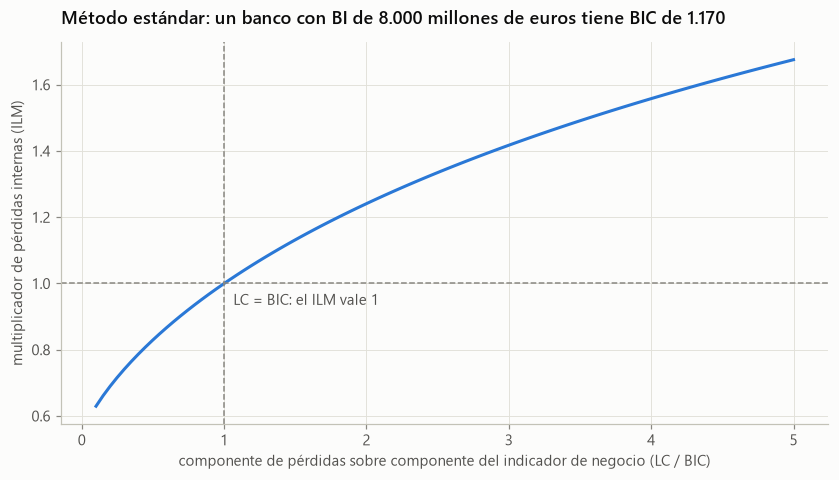

In [24]:
anual = frm.perdidas_operacionales(25, 2.0, 1.8, simulaciones=200_000, semilla=7)
cola_anual = pd.Series({"pérdida esperada": anual.mean(), "mediana": np.median(anual), "percentil 99%": np.quantile(anual, 0.99),
                        "percentil 99,9%": np.quantile(anual, 0.999)}, name="pérdida anual, millones de pesos")
print(cola_anual.round(0).to_string())
print(f"El percentil 99,9% es {cola_anual['percentil 99,9%'] / cola_anual['pérdida esperada']:.1f} veces la pérdida esperada")

rng = np.random.default_rng(8)
severidades = rng.lognormal(2.0, 1.8, 2_000)
ajuste = fa.ajustar_pot(severidades, np.quantile(severidades, 0.95))
estimacion = fa.var_es_pot(ajuste, 0.999)
verdadero = np.exp(2.0 + 1.8 * stats.norm.ppf(0.999))
print(f"\nPareto generalizada sobre el percentil 95: ξ = {ajuste['xi']:.2f}, β = {ajuste['beta']:.1f}, {ajuste['n_excesos']} excesos")
print(f"Cuantil 99,9% de la severidad: verdadero {verdadero:,.0f}; empírico {np.quantile(severidades, 0.999):,.0f}; Pareto generalizada {estimacion['var']:,.0f}")

bi = 8_000.0
bic = frm.componente_indicador_negocio(bi)
razones = np.linspace(0.1, 5, 100)
ilm = np.array([fa.multiplicador_perdidas_internas(r_ * bic, bic) for r_ in razones])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(razones, ilm, color=COLORES[0], linewidth=2)
ax.axhline(1, color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.axvline(1, color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.annotate("LC = BIC: el ILM vale 1", (1, 1), xytext=(6, -14), textcoords="offset points", color=TINTA_SECUNDARIA)
ax.set_xlabel("componente de pérdidas sobre componente del indicador de negocio (LC / BIC)")
ax.set_ylabel("multiplicador de pérdidas internas (ILM)")
ax.set_title(f"Método estándar: un banco con BI de 8.000 millones de euros tiene BIC de {bic:,.0f}".replace(",", "."))
plt.show()

**Lectura.**

- **La cola define el capital.** Con 25 eventos al año, la pérdida esperada es 934 millones, pero el percentil 99,9% llega a 9.609, diez veces más.
- **Estimar la cola es difícil.** Con 2.000 severidades, el cuantil empírico de 99,9%, 1.545, subestima el verdadero, 1.924, porque solo quedan dos observaciones más allá. La Pareto generalizada estimada con los 100 mayores excesos se acerca más, con 1.687, y aun así el error es grande.
- **El ILM premia y castiga el historial.** Con pérdidas que dupliquen el BIC, el capital sube 24%; con cinco veces, 68%. Con muy pocas pérdidas, baja hasta 37%.

### Ejercicios resueltos

**Ejercicio 7.1. Capital del método estándar** *(ejercicio propio)*

Un banco tiene un indicador de negocio de 35.000 millones de euros y una pérdida operacional anual promedio de 300 millones en los últimos 10 años. Calcula el BIC, el LC, el ILM y el capital.

In [25]:
resultado = fa.capital_riesgo_operacional(35_000, perdidas_anuales_promedio=300)
print(f"BIC = 1.000·12% + 29.000·15% + 5.000·18% = {resultado['bic']:,.0f}")
print(f"LC = 15 × 300 = {resultado['lc']:,.0f}; ILM = ln(e - 1 + ({resultado['lc']:,.0f}/{resultado['bic']:,.0f})^0,8) = {resultado['ilm']:.4f}")
print(f"Respuesta: capital = BIC × ILM = {resultado['capital']:,.1f} millones de euros.")

BIC = 1.000·12% + 29.000·15% + 5.000·18% = 5,370
LC = 15 × 300 = 4,500; ILM = ln(e - 1 + (4,500/5,370)^0,8) = 0.9503
Respuesta: capital = BIC × ILM = 5,103.0 millones de euros.


**Ejercicio 7.2. Frecuencia y severidad** *(ejercicio propio)*

Los eventos llegan con una Poisson de media 10 al año y cada uno cuesta en promedio 50, con desviación de 100. Calcula la media y la desviación de la pérdida anual, y verifica con una simulación.

In [26]:
lam_, m_, s_ = 10, 50.0, 100.0
media_l, var_l = lam_ * m_, lam_ * (s_**2 + m_**2)
mu_ln = np.log(m_**2 / np.sqrt(s_**2 + m_**2)); s_ln = np.sqrt(np.log(1 + s_**2 / m_**2))
sim = frm.perdidas_operacionales(lam_, mu_ln, s_ln, simulaciones=200_000, semilla=3)
print(f"Teórico: media λ·E[X] = {media_l:.0f}; varianza λ·E[X²] = {var_l:,.0f}; desviación {np.sqrt(var_l):.1f}")
print(f"Respuesta: la simulación con severidad lognormal da media {sim.mean():.1f} y desviación {sim.std():.1f}.")

Teórico: media λ·E[X] = 500; varianza λ·E[X²] = 125,000; desviación 353.6


Respuesta: la simulación con severidad lognormal da media 499.1 y desviación 358.6.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

La Teoría de Valores Extremos (TVE) se aplica en riesgo operacional para modelar:

- **A.** La cola de la distribución de severidad para pérdidas extremas, típicamente ajustada con una Distribución de Pareto Generalizada (GPD)
- **B.** La distribución normal del P&L diario
- **C.** La correlación de incumplimiento entre unidades de negocio
- **D.** La frecuencia de las pérdidas operacionales usando distribuciones de Poisson

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** La TVE ajusta la GPD a los excedentes por encima de un umbral alto (método de picos sobre umbral). Para el riesgo operacional, esto modela pérdidas muy grandes que una lognormal o normal podría subestimar. El parámetro de forma ξ de la GPD determina el grosor de la cola.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

El enfoque de distribución de pérdidas (LDA) para el capital de riesgo operacional estima la pérdida anual:

- **A.** usando solo la pérdida histórica promedio.
- **B.** ignorando los eventos de baja frecuencia y alta severidad.
- **C.** suponiendo que las pérdidas nunca superan la media.
- **D.** combinando una distribución de frecuencia (con qué frecuencia ocurren las pérdidas) con una de severidad (cuán grandes son), a menudo por Monte Carlo, para derivar una pérdida de alto cuantil.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** El LDA modela la frecuencia (p. ej., Poisson) y la severidad (p. ej., lognormal) por separado, y luego las convoluciona (a menudo por simulación) para construir la distribución de pérdida anual agregada. El capital operacional es un cuantil alto (p. ej., 99.9%) de esa distribución.

</details>

### Trampas frecuentes

- El riesgo operacional incluye el legal, pero no el estratégico ni el reputacional.
- En el método estándar, el ILM es 1 cuando las pérdidas son proporcionales al tamaño del negocio.
- Con severidades de cola pesada, el capital lo determinan los eventos raros y grandes, no los frecuentes.

## VRM-8. Pruebas de estrés

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Para qué.** Complementan al VaR y al ES, que miden días normales, con escenarios severos pero plausibles. Informan el capital, la liquidez, los límites y los planes de contingencia.
- **Escenarios.** Históricos (2008, la pandemia), hipotéticos y de sensibilidad a un factor. Deben ser coherentes: los factores se mueven juntos como lo harían en una crisis.
- **Prueba de estrés inversa.** Parte de un resultado, como perder el capital, y busca los escenarios que lo provocan. Con factores normales, el escenario más probable que produce una pérdida L es $x^* = -L\,\Sigma e/(e'\Sigma e)$, con e las exposiciones.
- **Gobierno.** El directorio aprueba y usa los resultados. Los principios de Basilea de 2018 piden escenarios relevantes para el modelo de negocio, revisión periódica y vínculo con la toma de decisiones.
- **Supervisión.** Pruebas regulatorias como las de la Reserva Federal y la Autoridad Bancaria Europea, y las del Banco Central de Chile en su Informe de Estabilidad Financiera.

### Análisis avanzado: prueba de estrés inversa con factores chilenos

La tesorería de FRM-3, con acciones del ETF IPSA, dólares y un bono a 10 años, quiere saber qué escenario de 10 días le haría perder $3.000 millones. Con la matriz de covarianza diaria de los factores desde 2019, escalada a 10 días, se calcula el escenario más probable con esa pérdida y su distancia de Mahalanobis. Luego se compara con episodios reales, cada uno medido con la covarianza escalada a su propia duración.

In [27]:
factores_e = pd.concat({"IPSA": r_ipsa, "dólar": dolar_alineado.pct_change(), "BCP 10 años, pb": bcp["10"].diff() * 100},
                       axis=1, sort=True).loc[r_ipsa.index].dropna()
exposiciones = np.array([20_000.0, 25 * spot, -12.0])
cov_diaria = factores_e.cov().to_numpy()
perdida_objetivo = 3_000.0
inverso = fa.estres_inverso(exposiciones, 10 * cov_diaria, perdida_objetivo)
print(f"Escenario más probable que pierde {perdida_objetivo:,.0f} en 10 días: IPSA {inverso['shocks'][0]:+.1%}, dólar {inverso['shocks'][1]:+.1%},"
      f" tasa a 10 años {inverso['shocks'][2]:+.0f} pb")
print(f"Distancia de Mahalanobis {inverso['distancia']:.2f}; probabilidad normal de una pérdida igual o mayor: {inverso['probabilidad_una_cola']:.2e}")

pnl_10d = (factores_e @ exposiciones).rolling(10).sum()
print(f"Peor resultado histórico de 10 días: {pnl_10d.min():,.0f} millones, terminado el {pnl_10d.idxmin():%d-%m-%Y}")

niveles_e = pd.concat({"IPSA": precios["ETF IPSA"], "dólar": dolar_alineado, "BCP 10 años": bcp["10"]}, axis=1, sort=True).ffill()
episodios = {"estallido social": ("2019-10-17", "2019-11-28"), "pandemia": ("2020-02-20", "2020-03-23"),
             "alzas de la TPM": ("2021-07-01", "2022-10-31"), "aranceles de 2025": ("2025-03-31", "2025-04-09")}
filas = {}
for nombre, (ini, fin) in episodios.items():
    a, b = niveles_e.loc[:ini].iloc[-1], niveles_e.loc[:fin].iloc[-1]
    x = np.array([b["IPSA"] / a["IPSA"] - 1, b["dólar"] / a["dólar"] - 1, (b["BCP 10 años"] - a["BCP 10 años"]) * 100])
    dias = len(factores_e.loc[ini:fin])
    distancia = float(np.sqrt(x @ np.linalg.solve(dias * cov_diaria, x)))
    filas[nombre] = {"días hábiles": dias, "IPSA": x[0], "dólar": x[1], "BCP 10 años, pb": x[2], "resultado": float(exposiciones @ x),
                     "distancia de Mahalanobis": distancia}
pd.DataFrame(filas).T.round(3)

Escenario más probable que pierde 3,000 en 10 días: IPSA -10.4%, dólar -2.8%, tasa a 10 años +20 pb
Distancia de Mahalanobis 3.01; probabilidad normal de una pérdida igual o mayor: 1.32e-03
Peor resultado histórico de 10 días: -6,825 millones, terminado el 23-03-2020


,días hábiles,IPSA,dólar,"BCP 10 años, pb",resultado,distancia de Mahalanobis
estallido social,29.0000,-0.1320,0.1610,24.2320,931.5740,3.7420
pandemia,23.0000,-0.3530,0.0700,20.8840,"-5,641.1860",5.2500
alzas de la TPM,305.0000,0.0440,0.2690,200.6780,"4,935.6180",2.4890
aranceles de 2025,8.0000,-0.0390,0.0490,-30.0000,768.8010,2.8780


**Lectura.**

- **El escenario más probable que hace perder 3.000 millones en 10 días** combina una caída de 10,4% del IPSA, una baja de 2,8% del dólar y un alza de 20 pb en la tasa a 10 años. Está a 3,0 desviaciones estándar: con normalidad, ocurriría una vez cada 30 años. Sin embargo, la peor pérdida histórica de 10 días fue de 6.825 millones, en marzo de 2020: las colas reales son más gruesas.
- **El escenario exige que el dólar caiga junto con el IPSA, lo contrario de lo habitual.** La posición en dólares cubre a las acciones, así que la cartera es más vulnerable cuando esa cobertura falla. Encontrar esa debilidad es el propósito de la prueba inversa.
- **De los episodios reales, solo la pandemia produjo una pérdida grande,** 5.641 millones, a 5,3 desviaciones. En el estallido social y en el ciclo de alzas de la TPM la cartera ganó gracias al dólar, aunque las tasas subieron 24 y 201 pb.

### Ejercicios resueltos

**Ejercicio 8.1. Pérdida de un escenario** *(ejercicio propio)*

Una cartera tiene $50.000 millones en acciones con beta 1,1, un bono con DV01 de $40 millones por punto base y una posición larga de USD 5 millones con el dólar a 950. En el escenario, el mercado cae 20%, las tasas suben 150 pb y el dólar sube 12%. ¿Cuánto pierde, en millones de pesos?

In [28]:
acciones_pnl = 50_000 * 1.1 * -0.20
bono_pnl = -40 * 150
dolares_pnl = 5 * 950 * 0.12
print(f"Acciones: 50.000 × 1,1 × (-20%) = {acciones_pnl:,.0f}; bono: -40 × 150 = {bono_pnl:,.0f}; dólares: 5 × 950 × 12% = {dolares_pnl:,.0f}")
print(f"Respuesta: resultado total {acciones_pnl + bono_pnl + dolares_pnl:,.0f} millones de pesos. Los dólares amortiguan muy poco frente al tamaño de las acciones.")

Acciones: 50.000 × 1,1 × (-20%) = -11,000; bono: -40 × 150 = -6,000; dólares: 5 × 950 × 12% = 570
Respuesta: resultado total -16,430 millones de pesos. Los dólares amortiguan muy poco frente al tamaño de las acciones.


**Ejercicio 8.2. Prueba de estrés inversa con dos factores** *(ejercicio propio)*

Una cartera tiene exposiciones de 100 y 50 a dos factores con varianzas de 0,04 y 0,09 y covarianza de 0,01. ¿Cuál es el escenario más probable que produce una pérdida de 30 y qué tan extremo es?

In [29]:
res = fa.estres_inverso(np.array([100.0, 50.0]), np.array([[0.04, 0.01], [0.01, 0.09]]), 30)
print(f"Shocks: {res['shocks'].round(4)}; pérdida comprobada: {-(np.array([100.0, 50.0]) @ res['shocks']):.1f}")
print(f"Respuesta: distancia {res['distancia']:.2f} desviaciones; con normalidad, una pérdida así o mayor tiene probabilidad {res['probabilidad_una_cola']:.2%}.")

Shocks: [-0.1862 -0.2276]; pérdida comprobada: 30.0
Respuesta: distancia 1.11 desviaciones; con normalidad, una pérdida así o mayor tiene probabilidad 13.26%.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

El reverse stress testing (prueba de estrés inversa) parte de:

- **A.** un resultado severo predefinido (como la insolvencia) y trabaja hacia atrás para identificar los escenarios que podrían causarlo.
- **B.** un escenario y calcula la pérdida que produce.
- **C.** la pérdida histórica promedio.
- **D.** solo la pérdida esperada.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** El stress testing convencional corre escenarios hacia adelante hasta las pérdidas. El inverso fija un resultado catastrófico (p. ej., la firma quiebra) y busca las combinaciones de shocks que lo producirían, revelando vulnerabilidades ocultas y dependencias de cola.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

Un gestor de riesgos usa pruebas de estrés para complementar los modelos de VaR. ¿Cuál de las siguientes describe mejor la limitación principal del VaR que las pruebas de estrés buscan atender?

- **A.** El VaR sobreestima las pérdidas en condiciones normales de mercado.
- **B.** El VaR requiere demasiadas observaciones para ser útil en la práctica.
- **C.** El VaR no da información sobre la magnitud de las pérdidas en la cola, más allá del umbral de confianza.
- **D.** El VaR no puede calcularse para instrumentos no lineales como las opciones.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** El VaR responde '¿cuál es la pérdida en el percentil X?' pero no dice nada sobre la severidad de las pérdidas más allá de ese punto. Un VaR al 99% solo indica que en el 1% de los días las pérdidas superan el umbral, no en cuánto. Las pruebas de estrés y el análisis de escenarios examinan explícitamente escenarios extremos pero plausibles para entender la severidad del riesgo de cola. El Expected Shortfall también aborda esto parcialmente.

</details>

### Trampas frecuentes

- La prueba de estrés inversa parte de la pérdida y busca el escenario; la tradicional hace lo contrario.
- Un escenario de estrés debe ser coherente: no basta con mover cada factor a su peor nivel por separado.
- Las pruebas de estrés no reemplazan al VaR: lo complementan con eventos fuera de la muestra.

## VRM-9. Convenciones de precio, descuento y arbitraje

*Relevancia en el examen: media. Dificultad: intermedia.*

### Idea central

- **Cotizaciones.** Los bonos se cotizan en precio limpio por 100 de nominal; el comprador paga el precio sucio, limpio más intereses devengados. Las letras del Tesoro de EE.UU. se cotizan con una tasa de descuento bancario: $P = 100(1 - d \cdot \text{días}/360)$.
- **Factores de descuento.** El valor hoy de un peso pagado en t. Con bonos de cupón se obtienen resolviendo un sistema de ecuaciones.
- **Ley de un solo precio.** Dos carteras con los mismos flujos deben costar lo mismo. Si no, se vende la cara y se compra la barata: arbitraje.
- **Replicación.** Un bono se replica con otros si sus flujos son combinación lineal de los de ellos. Las cantidades se obtienen resolviendo $F'q = c$.
- **Valoración neutral al riesgo.** Descontar a la tasa libre de riesgo el pago esperado con probabilidades neutrales al riesgo. No supone que los inversionistas sean neutrales al riesgo.

### Análisis avanzado: factores de descuento implícitos y un arbitraje de bonos

Con la curva swap cámara de FMP-16 se valoran seis bonos de cupón anual a 1, 2, 3, 4 y 5 años, dos de ellos a 3 años, y a uno de estos se le suma un error de precio de 0,60. Primero se estiman los factores de descuento por mínimos cuadrados con los seis precios; luego se replican los flujos del bono mal valorado con los otros cinco y se arma el arbitraje.

In [30]:
fecha_curva = swap.dropna().index[-1]
tasas_swap = swap.loc[fecha_curva] / 100
df_06m = 1 / (1 + tasas_swap["0.5"] * 0.5 * 365 / 360)
df_1a = 1 / (1 + tasas_swap["1"] * 365 / 360)
par_1a = 2 * (1 - df_1a) / (df_06m + df_1a)
plazos_curva = np.arange(1, 21) / 2
par_rejilla = np.interp(plazos_curva, [1, 2, 3, 4, 5, 10],
                        [par_1a, tasas_swap["2"], tasas_swap["3"], tasas_swap["4"], tasas_swap["5"], tasas_swap["10"]])
factores = fa.bootstrap_par(plazos_curva, par_rejilla, 2, factores_conocidos=[df_06m, df_1a])
df_anual = factores[[1, 3, 5, 7, 9]]

cupones = [0.04, 0.05, 0.055, 0.06, 0.05, 0.07]
vencimientos = [1, 2, 3, 4, 5, 3]
flujos = np.zeros((6, 5))
for i, (c, m) in enumerate(zip(cupones, vencimientos)):
    flujos[i, :m] = 100 * c
    flujos[i, m - 1] += 100
justos = flujos @ df_anual
mercado = justos.copy()
mercado[5] += 0.60
estimacion = fa.factores_desde_bonos(flujos, mercado)
nombres_bonos = [f"{c:.1%} a {m} años".replace(".", ",") for c, m in zip(cupones, vencimientos)]
print(pd.DataFrame({"precio de mercado": mercado, "residuo de mínimos cuadrados": estimacion["residuos"]}, index=nombres_bonos).round(4).to_string())

cantidades = fa.replicar_flujos(flujos[5], flujos[:5])
costo_replica = float(cantidades @ mercado[:5])
print("\nCantidades de los otros bonos que replican el 7% a 3 años:", np.round(cantidades, 4))
print(f"Costo de la réplica {costo_replica:.4f}; precio de mercado del bono {mercado[5]:.4f}")
print(f"Arbitraje: vender el bono caro y comprar la réplica deja {mercado[5] - costo_replica:.4f} hoy y flujos netos futuros"
      f" de {np.abs(cantidades @ flujos[:5] - flujos[5]).max():.1e}")

               precio de mercado  residuo de mínimos cuadrados
4,0% a 1 años            99.1888                       -0.0039
5,0% a 2 años            99.6093                       -0.0040
5,5% a 3 años           100.3059                       -0.2999
6,0% a 4 años           101.7163                       -0.0000
5,0% a 5 años            97.3649                       -0.0000
7,0% a 3 años           104.9723                        0.2957

Cantidades de los otros bonos que replican el 7% a 3 años: [0.013  0.0135 1.0142 0.     0.    ]
Costo de la réplica 104.3723; precio de mercado del bono 104.9723
Arbitraje: vender el bono caro y comprar la réplica deja 0.6000 hoy y flujos netos futuros de 0.0e+00


**Lectura.**

- **Los mínimos cuadrados detectan la inconsistencia, pero no al culpable.** Los dos bonos a 3 años quedan con residuos de −0,30 y +0,30: el error se reparte entre ellos.
- **La replicación resuelve el problema.** Los flujos del bono de 7% se replican con 1,01 unidades del bono de 5,5% más pequeñas cantidades de los bonos a 1 y 2 años. La réplica cuesta 104,37 y el bono 104,97: vender el bono y comprar la réplica deja 0,60 hoy, sin ningún flujo futuro.
- **En la práctica, las diferencias pequeñas** suelen deberse a liquidez, impuestos o costos de transacción, no a arbitrajes reales.

### Ejercicios resueltos

**Ejercicio 9.1. Precio con tasas spot** *(ejercicio propio)*

Un bono a 2 años paga cupón anual de 6% sobre 100. Las tasas spot anuales a 1 y 2 años son 4,5% y 5,2%. ¿Cuál es su precio de no arbitraje y su rendimiento al vencimiento?

In [31]:
precio_9 = 6 / 1.045 + 106 / 1.052**2
print(f"Precio = 6/1,045 + 106/1,052² = {precio_9:.4f}")
print(f"Respuesta: rendimiento al vencimiento = {fa.rendimiento_bono(precio_9, 0.06, 2, 1):.4%}, un promedio ponderado de las dos tasas spot.")

Precio = 6/1,045 + 106/1,052² = 101.5215
Respuesta: rendimiento al vencimiento = 5.1796%, un promedio ponderado de las dos tasas spot.


**Ejercicio 9.2. Letra del Tesoro con tasa de descuento** *(ejercicio propio)*

Una letra a 90 días cotiza con una tasa de descuento bancario de 5%. ¿Cuál es su precio por 100 y su rendimiento equivalente del mercado monetario (actual/360)?

In [32]:
precio_letra = 100 * (1 - 0.05 * 90 / 360)
rendimiento_mm = (100 / precio_letra - 1) * 360 / 90
print(f"Precio = 100 × (1 - 5% × 90/360) = {precio_letra:.4f}")
print(f"Respuesta: rendimiento del mercado monetario = (100/{precio_letra:.2f} - 1) × 360/90 = {rendimiento_mm:.4%}, mayor que la tasa de descuento.")

Precio = 100 × (1 - 5% × 90/360) = 98.7500
Respuesta: rendimiento del mercado monetario = (100/98.75 - 1) × 360/90 = 5.0633%, mayor que la tasa de descuento.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Un bono a 2 años paga un cupón anual de 5% sobre \$100 de nominal. La tasa spot a 1 año es 4% y a 2 años 5%. Su precio libre de arbitraje es más cercano a:

- **A.** $100.00
- **B.** $102.00
- **C.** $98.17
- **D.** $100.05

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Se descuenta cada flujo a la tasa spot correspondiente: $P = \dfrac{5}{1.04} + \dfrac{105}{1.05^2} = 4.81 + 95.24 \approx \$100.05$.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

Bajo el marco de valoración neutral al riesgo, los activos se valoran mediante:

- **A.** Usar la medida de probabilidad física con prima de riesgo
- **B.** Aplicar el costo de capital propio del CAPM
- **C.** Descontar los flujos de caja esperados al WACC
- **D.** Descontar los pagos esperados neutrales al riesgo a la tasa libre de riesgo

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Valoración neutral al riesgo: V₀ = e^(−rT) × E^Q[V_T] donde E^Q denota la esperanza bajo la medida neutral al riesgo (medida Q). Bajo Q, el drift de todos los activos es igual a la tasa libre de riesgo. Es la base de la valoración de derivados (BSM, árboles binomiales).

</details>

### Trampas frecuentes

- La tasa de descuento bancario se calcula sobre el valor nominal, no sobre el precio: subestima el rendimiento.
- El precio limpio no incluye los intereses devengados; el que se paga es el sucio.
- Valorar en la medida neutral al riesgo no supone inversionistas neutrales al riesgo.

## VRM-10. Tasas de interés

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Spot, forward y par.** Las tasas spot descuentan flujos únicos; las forward son las implícitas entre dos fechas futuras; la par es el cupón que deja un bono en 100. Conociendo una de las tres curvas se obtienen las otras.
- **Relaciones.** Con curva creciente, forward > spot > par; con curva invertida, al revés. Una tasa spot es un promedio de las forward hasta su plazo.
- **Bootstrapping.** Las tasas spot se obtienen secuencialmente desde los bonos de menor plazo.
- **Formas de la curva.** Creciente, invertida, plana o con joroba. Una curva invertida suele anticipar recortes de tasas y, a veces, recesiones.
- **Rendimiento por mantener (carry) y por deslizamiento (roll-down).** Si la curva no cambia, un bono gana su rendimiento y además sube de precio al acercarse a plazos con tasa menor.

### Análisis avanzado: forwards, pendiente e inversión de la curva chilena

Con las tasas swap cámara mensuales desde 2008 se calculan la pendiente entre 10 años y 1 año y la tasa forward a 5 años dentro de 5 años, tratando las tasas swap como tasas spot anuales para simplificar.

La curva estuvo invertida en 15% de los meses; la mayor inversión fue -4.37% en 09-2022
Forward 5 años en 5 años: promedio 5.39%, entre 3.00% y 7.74%; hoy 6.26%


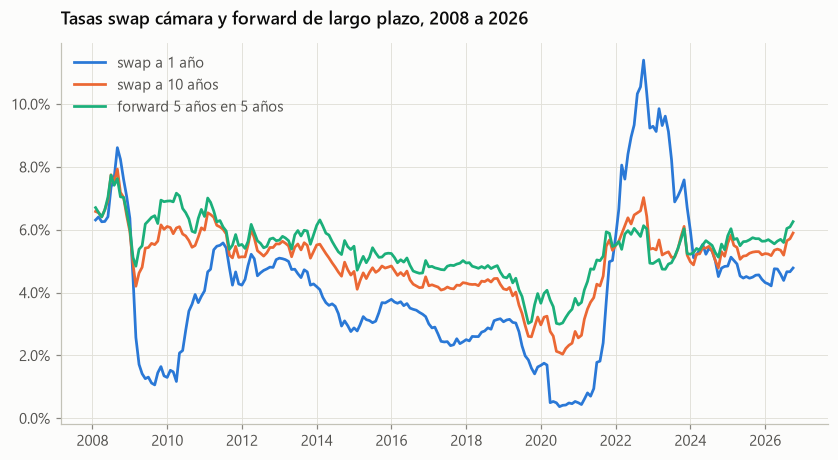

,1,5,10,forward 5 años en 5 años,pendiente 10 - 1
fecha,,,,,
2008-12-31,0.0637,0.0585,0.0594,0.0604,-0.0042
2013-12-31,0.0419,0.0490,0.0552,0.0614,0.0133
2019-12-31,0.0169,0.0229,0.0297,0.0366,0.0129
2020-12-31,0.0050,0.0153,0.0256,0.0361,0.0206
2022-12-31,0.0930,0.0590,0.0541,0.0493,-0.0388
2023-12-31,0.0598,0.0474,0.0498,0.0522,-0.0100
2025-12-31,0.0432,0.0485,0.0524,0.0564,0.0092


In [33]:
curva_m = swap[["1", "5", "10"]].resample("ME").last().dropna() / 100
curva_m["forward 5 años en 5 años"] = ((1 + curva_m["10"]) ** 10 / (1 + curva_m["5"]) ** 5) ** (1 / 5) - 1
curva_m["pendiente 10 - 1"] = curva_m["10"] - curva_m["1"]
invertida = curva_m["pendiente 10 - 1"] < 0
print(f"La curva estuvo invertida en {invertida.mean():.0%} de los meses; la mayor inversión fue {curva_m['pendiente 10 - 1'].min():.2%}"
      f" en {curva_m['pendiente 10 - 1'].idxmin():%m-%Y}")
print(f"Forward 5 años en 5 años: promedio {curva_m['forward 5 años en 5 años'].mean():.2%}, entre {curva_m['forward 5 años en 5 años'].min():.2%}"
      f" y {curva_m['forward 5 años en 5 años'].max():.2%}; hoy {curva_m['forward 5 años en 5 años'].iloc[-1]:.2%}")

fig, ax = plt.subplots(figsize=(9, 4.5))
for color, (columna, etiqueta) in zip(COLORES, [("1", "swap a 1 año"), ("10", "swap a 10 años"), ("forward 5 años en 5 años", "forward 5 años en 5 años")]):
    ax.plot(curva_m.index, curva_m[columna], color=color, linewidth=1.8, label=etiqueta)
eje_porcentaje(ax, decimales=1)
ax.set_title("Tasas swap cámara y forward de largo plazo, 2008 a 2026")
ax.legend(loc="upper left")
plt.show()
fin_de_anio = curva_m.resample("YE").last()
fin_de_anio[fin_de_anio.index.year.isin([2008, 2013, 2019, 2020, 2022, 2023, 2025])].round(4)

**Lectura.**

- **La curva chilena estuvo invertida en 15% de los meses desde 2008.** La mayor inversión fue en septiembre de 2022, en el máximo del ciclo de alzas: la tasa a un año superaba en 4,4 puntos a la de 10 años.
- **La forward de largo plazo es mucho más estable que la tasa corta.** La forward a 5 años dentro de 5 años promedió 5,4% y se movió entre 3,0% y 7,7%, mientras la tasa a un año fue de 0,4% a 11,4%. El mercado espera que la política monetaria vuelva a un nivel neutral.
- **Hoy la forward 5 en 5, de 6,3%, está sobre su promedio histórico:** incluye una prima por plazo alta o expectativas de tasas largas mayores.

### Ejercicios resueltos

**Ejercicio 10.1. Forward y tasa par desde factores de descuento** *(banco de ejercicios de frm-prep)*

Los factores de descuento a 1, 2 y 3 años son 0,95, 0,90 y 0,85. Calcula la forward a un año dentro de un año, las tasas spot y la tasa par a 3 años con cupón anual.

In [34]:
d3 = np.array([0.95, 0.90, 0.85])
spots = d3 ** (-1 / np.arange(1, 4)) - 1
print(f"Forward 1 año en 1 año = 0,95/0,90 - 1 = {0.95 / 0.90 - 1:.4%}; spots = {np.round(spots * 100, 4)}%")
print(f"Respuesta: tasa par a 3 años = (1 - 0,85) / (0,95 + 0,90 + 0,85) = {(1 - 0.85) / d3.sum():.4%}")

Forward 1 año en 1 año = 0,95/0,90 - 1 = 5.5556%; spots = [5.2632 5.4093 5.5667]%
Respuesta: tasa par a 3 años = (1 - 0,85) / (0,95 + 0,90 + 0,85) = 5.5556%


**Ejercicio 10.2. Bootstrapping a mano** *(ejercicio propio)*

Los bonos par a 1, 2 y 3 años, con cupón anual, rinden 4%, 4,5% y 5%. Obtén los factores de descuento y las tasas spot.

In [35]:
factores_10 = fa.bootstrap_par(np.array([1.0, 2.0, 3.0]), np.array([0.04, 0.045, 0.05]), frecuencia=1)
print(f"Factores: {np.round(factores_10, 6)}")
print(f"Respuesta: spots = {np.round((factores_10 ** (-1 / np.arange(1, 4)) - 1) * 100, 4)}%: con curva par creciente, las spot quedan algo más arriba.")

Factores: [0.961538 0.915532 0.862997]
Respuesta: spots = [4.     4.5113 5.0341]%: con curva par creciente, las spot quedan algo más arriba.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

El factor de descuento a 1 año es 0.96 y a 2 años es 0.90. La tasa forward a 1 año para el segundo año es más cercana a:

- **A.** 4.17%
- **B.** 5.00%
- **C.** 6.00%
- **D.** 6.67%

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** El factor de descuento forward es $\dfrac{DF_2}{DF_1} = \dfrac{0.90}{0.96} = 0.9375$, así $f = \dfrac{DF_1}{DF_2} - 1 = \dfrac{0.96}{0.90} - 1 \approx 6.67\%$.

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad intermedia)*

Los factores de descuento a 1, 2 y 3 años son 0,97, 0,93 y 0,88. ¿Cuál es la tasa par a 3 años con cupón anual?

- **A.** 4,00%
- **B.** 4,35%
- **C.** 4,32%
- **D.** 4,17%

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** La tasa par c cumple c·(DF₁ + DF₂ + DF₃) + DF₃ = 1, así que c = (1 − 0,88) / (0,97 + 0,93 + 0,88) = 0,12 / 2,78 = 4,32%. El 4,35% es la tasa cero a 3 años, 0,88^(−1/3) − 1. Con una curva creciente, la tasa par queda bajo la tasa cero del mismo plazo.

</details>

### Trampas frecuentes

- Con curva creciente, la tasa par queda bajo la spot y la forward sobre ambas.
- Una tasa spot es un promedio geométrico de las forward hasta su plazo.
- La forward no es un pronóstico puro: incluye primas por plazo.

## VRM-11. Rendimientos de bonos y cálculo de retornos

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Rendimiento al vencimiento.** La tasa interna de retorno de los flujos del bono. Supone reinvertir los cupones a esa misma tasa.
- **Retorno realizado.** Depende de la tasa de reinversión y del precio de venta; puede diferir mucho del rendimiento al comprar.
- **Anualidades y perpetuidades.** $PV = C\,\frac{1 - (1+y)^{-n}}{y}$ y $PV = C/y$; con crecimiento g, $C/(y - g)$.
- **Descomposición del resultado.** Carry (cupón y acumulación), roll-down (el bono se acerca a plazos de distinta tasa), cambio de tasas y cambio de spread.
- **Spreads.** Sobre el rendimiento de un bono de referencia, sobre la curva cero (Z-spread) y ajustado por opciones (OAS).

### Análisis avanzado: carry, roll-down y cambio de tasas en el BCP a 10 años

Cada comienzo de año desde 2008 se compra un bono a 10 años con cupón anual igual a la tasa del BCP a 10 años, a la par, y se vende un año después como bono a 9 años. La tasa a 9 años se interpola entre las de 5 y 10 años. El retorno se separa en carry (el cupón), roll-down (el cambio de precio si la curva no se moviera) y cambio de tasas.

In [36]:
inicio_anual = bcp[["5", "10"]].resample("YS").first().dropna() / 100
filas = []
for i in range(len(inicio_anual) - 1):
    hoy, en_un_anio = inicio_anual.iloc[i], inicio_anual.iloc[i + 1]
    cupon = hoy["10"]
    y9_hoy = hoy["5"] + (hoy["10"] - hoy["5"]) * 4 / 5
    y9_fin = en_un_anio["5"] + (en_un_anio["10"] - en_un_anio["5"]) * 4 / 5
    precio_roll = fa.precio_bono(cupon, y9_hoy, 9, 1)
    precio_fin = fa.precio_bono(cupon, y9_fin, 9, 1)
    filas.append({"año": inicio_anual.index[i].year, "tasa al comprar": cupon, "carry": cupon, "roll-down": precio_roll / 100 - 1,
                  "cambio de tasas": (precio_fin - precio_roll) / 100, "retorno total": cupon + precio_fin / 100 - 1})
retornos_bono = pd.DataFrame(filas).set_index("año")
print(f"Promedios {retornos_bono.index[0]} a {retornos_bono.index[-1]}:")
print(retornos_bono.mean().map("{:.2%}".format).to_string())
print(f"Desviación estándar del retorno total {retornos_bono['retorno total'].std():.2%}; del componente de tasas {retornos_bono['cambio de tasas'].std():.2%}")
retornos_bono.map("{:.2%}".format)

Promedios 2008 a 2025:
tasa al comprar    5.05%
carry              5.05%
roll-down          0.44%
cambio de tasas    0.52%
retorno total      6.01%
Desviación estándar del retorno total 7.18%; del componente de tasas 6.95%


,tasa al comprar,carry,roll-down,cambio de tasas,retorno total
año,,,,,
2008,6.36%,6.36%,0.07%,3.25%,9.67%
2009,5.86%,5.86%,-0.11%,-2.11%,3.65%
2010,6.39%,6.39%,1.39%,0.10%,7.88%
2011,6.18%,6.18%,0.02%,7.29%,13.48%
2012,5.19%,5.19%,0.34%,-2.64%,2.88%
2013,5.52%,5.52%,-0.01%,2.84%,8.35%
2014,5.20%,5.20%,0.57%,6.35%,12.12%
2015,4.35%,4.35%,0.70%,-2.22%,2.84%
2016,4.59%,4.59%,0.23%,3.08%,7.91%


**Lectura.**

- **El carry explica el retorno promedio; las tasas, la variabilidad.** Desde 2008, comprar el BCP a 10 años y venderlo un año después rindió 6,0% al año: 5,05% de carry, 0,44% de roll-down y 0,52% por cambios de tasas. Pero la desviación del componente de tasas, 6,95%, es casi toda la del retorno total, 7,18%.
- **El peor año fue 2021, con −18,4%,** cuando la tasa a 10 años subió con fuerza; el mejor, 2019, con +15,4%, cuando bajó.
- **El roll-down fue pequeño** porque la curva entre 5 y 10 años suele ser bastante plana.

### Ejercicios resueltos

**Ejercicio 11.1. Rendimiento al vencimiento como tasa interna de retorno** *(caso de prueba de los motores de cálculo de frm-prep)*

Un bono a 5 años con cupón semestral de 4% anual cotiza a 95. Calcula su rendimiento al vencimiento con el despeje de precio y, como verificación, con la TIR de sus flujos usando la función portada de frm-prep.

In [37]:
ytm = fa.rendimiento_bono(95, 0.04, 5, 2)
flujos_11 = np.array([-95] + [2] * 9 + [102])
tir_semestral = fa.tir(flujos_11)
print(f"Rendimiento al vencimiento: {ytm:.4%}; TIR semestral {tir_semestral:.4%} × 2 = {2 * tir_semestral:.4%}")
print("Respuesta: coinciden, porque el rendimiento al vencimiento es la TIR de los flujos, anualizada con la convención semestral.")

Rendimiento al vencimiento: 5.1469%; TIR semestral 2.5735% × 2 = 5.1469%
Respuesta: coinciden, porque el rendimiento al vencimiento es la TIR de los flujos, anualizada con la convención semestral.


**Ejercicio 11.2. Retorno realizado y reinversión** *(ejercicio propio)*

Compras a la par un bono a 3 años con cupón anual de 5%. Si los cupones se reinvierten al 2%, ¿cuál es el retorno anual realizado al vencimiento? ¿Y si se reinvierten al 8%?

In [38]:
for tasa in (0.02, 0.05, 0.08):
    final = 5 * (1 + tasa) ** 2 + 5 * (1 + tasa) + 105
    print(f"Reinversión al {tasa:.0%}: valor final {final:.2f}; retorno realizado {(final / 100) ** (1 / 3) - 1:.3%}")
print("Respuesta: solo si los cupones se reinvierten al 5% el retorno realizado iguala al rendimiento al comprar.")

Reinversión al 2%: valor final 115.30; retorno realizado 4.861%
Reinversión al 5%: valor final 115.76; retorno realizado 5.000%
Reinversión al 8%: valor final 116.23; retorno realizado 5.142%
Respuesta: solo si los cupones se reinvierten al 5% el retorno realizado iguala al rendimiento al comprar.


**Ejercicio 11.3. Anualidad y perpetuidad** *(ejercicio propio)*

Una perpetuidad paga 5 al año con tasa de 4%: ¿cuánto vale? ¿Y si los pagos crecen 1% al año? ¿Cuánto vale una anualidad de 30 pagos de 5 con la misma tasa?

In [39]:
print(f"Perpetuidad = 5 / 4% = {5 / 0.04:.2f}; con crecimiento = 5 / (4% - 1%) = {5 / 0.03:.2f}")
print(f"Respuesta: anualidad de 30 años = {fa.valor_presente(30, 0.04, pago=-5):.2f}, 69% del valor de la perpetuidad.")

Perpetuidad = 5 / 4% = 125.00; con crecimiento = 5 / (4% - 1%) = 166.67
Respuesta: anualidad de 30 años = 86.46, 69% del valor de la perpetuidad.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

El rendimiento al peor (yield-to-worst, YTW) de un bono rescatable es:

- **A.** Lo mismo que el rendimiento al vencimiento
- **B.** El rendimiento suponiendo un rescate inmediato
- **C.** El rendimiento suponiendo que el bono nunca se rescata
- **D.** El menor rendimiento entre el rendimiento al vencimiento y los rendimientos al rescate en cada fecha de call

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** YTW = min(YTM, YTC en cada fecha de rescate). Representa el rendimiento en el peor caso que obtendrá el inversor si el emisor ejerce el call en el momento más desfavorable. Los inversores usan el YTW como estimación conservadora para bonos rescatables.

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad avanzada)*

Compras a la par un bono a 2 años con cupón anual de 6%. El primer cupón se reinvierte al 3% durante un año. ¿Cuál es el retorno anual realizado hasta el vencimiento?

- **A.** 5,91%
- **B.** 6,09%
- **C.** 6,00%
- **D.** 4,50%

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Valor final = 6 × 1,03 + 106 = 112,18. Retorno realizado = (112,18/100)^(1/2) − 1 = 5,91%. Queda bajo el rendimiento al vencimiento de 6% porque el cupón se reinvirtió a una tasa menor: es el riesgo de reinversión.

</details>

### Trampas frecuentes

- El rendimiento al vencimiento supone reinvertir los cupones a esa misma tasa; el retorno realizado no.
- El roll-down solo suma retorno si la curva tiene pendiente positiva y no se mueve.
- El rendimiento al peor de un bono rescatable es el menor entre el rendimiento al vencimiento y al rescate.

## VRM-12. Aplicación de la duración, la convexidad y el DV01

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **DV01.** Cambio de precio ante una baja de un punto base: $DV01 = D_{mod} \times P \times 0,0001$. Es aditivo entre posiciones y es la base de las coberturas.
- **Duración.** Macaulay es el plazo promedio ponderado de los flujos; la modificada, $D_{Mac}/(1 + y/m)$, es la sensibilidad porcentual del precio. La efectiva se calcula revaluando: $D_{ef} = \frac{P_- - P_+}{2P_0\Delta y}$, y sirve para bonos con opciones.
- **Convexidad.** $\frac{\Delta P}{P} \approx -D\Delta y + \frac{1}{2}C(\Delta y)^2$. La convexidad efectiva es $\frac{P_+ + P_- - 2P_0}{P_0(\Delta y)^2}$; los bonos con opciones de rescate y los MBS pueden tener convexidad negativa.
- **Coberturas.** Cubrir por DV01 iguala la sensibilidad a un desplazamiento paralelo. La razón de cobertura es $DV01_{cubierto}/DV01_{cobertura}$.
- **Barbell y bullet.** Con el mismo valor y la misma duración, una cartera de extremos (barbell) tiene más convexidad que una concentrada en el plazo medio (bullet). Gana con movimientos paralelos grandes, pero suele rendir menos y está expuesta a cambios de pendiente.

### Análisis avanzado: barbell frente a bullet con la curva del Banco Central

Con las tasas del BCP de hoy se arman bonos par de cupón anual a 2, 5 y 10 años. La cartera bullet tiene 100 en el bono a 5 años; la barbell combina los de 2 y 10 años con el mismo valor y la misma duración modificada. Se comparan bajo desplazamientos paralelos y bajo cambios de pendiente.

Tasas BCP del 22-09-2026: 2 años 5.12%, 5 años 5.56%, 10 años 5.97%
Barbell: 56.3% en 2 años y 43.7% en 10 años. Duración 4.26 en ambas; convexidad bullet 23.4, barbell 33.5
Rendimiento ponderado: bullet 5.56%; barbell 5.49%


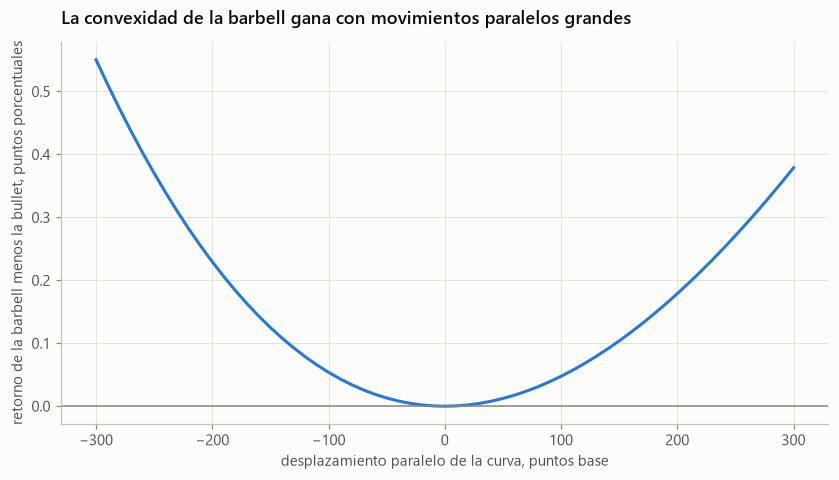

,bullet,barbell,diferencia
paralelo +100 pb,-4.15%,-4.10%,+0.05%
paralelo -100 pb,+4.38%,+4.44%,+0.05%
"empinamiento: 2 años -50, 10 años +50",-0.00%,-1.04%,-1.04%
"aplanamiento: 2 años +50, 10 años -50",-0.00%,+1.13%,+1.13%
mariposa: 5 años +50,-2.10%,-0.00%,+2.10%


In [40]:
tasas_bcp = bcp.dropna().iloc[-1] / 100
metricas = {p: fa.metricas_bono(tasas_bcp[str(p)], tasas_bcp[str(p)], p, 1) for p in (2, 5, 10)}
d2, d5, d10 = (metricas[p]["modificada"] for p in (2, 5, 10))
peso_10 = (d5 - d2) / (d10 - d2)
pesos_barbell = {2: 1 - peso_10, 10: peso_10}
conv_barbell = sum(w * metricas[p]["convexidad"] for p, w in pesos_barbell.items())
print(f"Tasas BCP del {bcp.dropna().index[-1]:%d-%m-%Y}: 2 años {tasas_bcp['2']:.2%}, 5 años {tasas_bcp['5']:.2%}, 10 años {tasas_bcp['10']:.2%}")
print(f"Barbell: {pesos_barbell[2]:.1%} en 2 años y {pesos_barbell[10]:.1%} en 10 años. Duración {d5:.2f} en ambas;"
      f" convexidad bullet {metricas[5]['convexidad']:.1f}, barbell {conv_barbell:.1f}")
print(f"Rendimiento ponderado: bullet {tasas_bcp['5']:.2%}; barbell {pesos_barbell[2] * tasas_bcp['2'] + pesos_barbell[10] * tasas_bcp['10']:.2%}")

def retorno(plazo, cambio):
    return fa.precio_bono(tasas_bcp[str(plazo)], tasas_bcp[str(plazo)] + cambio, plazo, 1) / 100 - 1

def resultado_barbell(cambio_2, cambio_10):
    return pesos_barbell[2] * retorno(2, cambio_2) + pesos_barbell[10] * retorno(10, cambio_10)

desplazamientos = np.arange(-300, 301, 10) / 10_000
diferencia = [resultado_barbell(c, c) - retorno(5, c) for c in desplazamientos]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(desplazamientos * 10_000, np.array(diferencia) * 100, color=COLORES[0], linewidth=2)
ax.axhline(0, color=TINTA_TENUE, linewidth=1)
ax.set_xlabel("desplazamiento paralelo de la curva, puntos base")
ax.set_ylabel("retorno de la barbell menos la bullet, puntos porcentuales")
ax.set_title("La convexidad de la barbell gana con movimientos paralelos grandes")
plt.show()
escenarios_curva = {"paralelo +100 pb": (0.01, 0.01, 0.01), "paralelo -100 pb": (-0.01, -0.01, -0.01),
                    "empinamiento: 2 años -50, 10 años +50": (-0.005, 0.0, 0.005), "aplanamiento: 2 años +50, 10 años -50": (0.005, 0.0, -0.005),
                    "mariposa: 5 años +50": (0.0, 0.005, 0.0)}
pd.DataFrame({nombre: {"bullet": retorno(5, c5), "barbell": resultado_barbell(c2, c10)}
              for nombre, (c2, c5, c10) in escenarios_curva.items()}).T.assign(diferencia=lambda t: t["barbell"] - t["bullet"]).map("{:+.2%}".format)

**Lectura.**

- **La convexidad se paga.** Con el mismo valor y duración, la barbell tiene 43% más convexidad que la bullet, 33,5 frente a 23,4, pero rinde 7 pb menos.
- **Con desplazamientos paralelos, la barbell siempre gana:** 0,05 puntos con ±100 pb y hasta 0,55 con −300 pb.
- **Los cambios de forma dominan.** Un empinamiento de ±50 pb le hace perder 1,04 puntos frente a la bullet; un aplanamiento, ganar 1,13; y un alza de 50 pb solo en el plazo de 5 años le da una ventaja de 2,1 puntos. Elegir entre barbell y bullet es una apuesta sobre la forma de la curva más que sobre su nivel.

### Ejercicios resueltos

**Ejercicio 12.1. Duración, DV01 y convexidad** *(banco de ejercicios de frm-prep)*

Un bono tiene duración de Macaulay de 4,5 y rinde 6% anual: ¿cuál es su duración modificada? Otro, con precio 100 y duración modificada 5, ¿qué DV01 tiene? Un bono con duración modificada 7 y convexidad 100, ¿cuánto cambia si las tasas suben 100 pb? Y uno con precio 100, duración 6 y convexidad 90, ¿qué precio tiene si suben 150 pb?

In [41]:
print(f"Duración modificada = 4,5 / 1,06 = {4.5 / 1.06:.2f}")
print(f"DV01 = 5 × 100 × 0,0001 = {frm.dv01(100, 5):.2f}")
print(f"ΔP/P = -7 × 1% + ½ × 100 × 1%² = {fa.cambio_precio_aproximado(7, 100, 0.01):.2%}")
print(f"Respuesta: nuevo precio = 100 × (1 - 6 × 1,5% + ½ × 90 × 1,5%²) = {100 * (1 + fa.cambio_precio_aproximado(6, 90, 0.015)):.2f}")

Duración modificada = 4,5 / 1,06 = 4.25
DV01 = 5 × 100 × 0,0001 = 0.05
ΔP/P = -7 × 1% + ½ × 100 × 1%² = -6.50%
Respuesta: nuevo precio = 100 × (1 - 6 × 1,5% + ½ × 90 × 1,5%²) = 92.01


**Ejercicio 12.2. Cobertura por DV01** *(ejercicio propio)*

Con las tasas del BCP de hoy, ¿cuánto nominal del bono a 2 años hay que vender para cubrir $1.000 millones del bono a 10 años contra un desplazamiento paralelo?

In [42]:
razon = metricas[10]["dv01"] / metricas[2]["dv01"]
print(f"DV01 por 100: 10 años {metricas[10]['dv01']:.4f}; 2 años {metricas[2]['dv01']:.4f}")
print(f"Respuesta: vender {razon * 1_000:,.0f} millones del bono a 2 años: {razon:.2f} veces el nominal cubierto.")

DV01 por 100: 10 años 0.0737; 2 años 0.0186
Respuesta: vender 3,971 millones del bono a 2 años: 3.97 veces el nominal cubierto.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Un bono valuado en \$100 sube a \$100.60 cuando los rendimientos bajan 10 pb y cae a \$99.50 cuando suben 10 pb. Su convexidad efectiva es más cercana a:

- **A.** 1,000
- **B.** 100
- **C.** 500
- **D.** 5,000

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** $C_{ef} = \dfrac{V_{+} + V_{-} - 2V_0}{V_0 (\Delta y)^2} = \dfrac{99.50 + 100.60 - 200}{100 (0.001)^2} = \dfrac{0.10}{0.0001} = 1{,}000$.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Una cartera barbell consiste en bonos de corto y largo plazo, mientras que una cartera bullet concentra el vencimiento en un horizonte único intermedio. Ambas carteras se construyen para tener el mismo valor de mercado y la misma duración. ¿Cuál es la principal ventaja de la cartera barbell sobre la cartera bullet?

- **A.** La cartera barbell tiene mayor convexidad que la cartera bullet, lo que significa que se beneficia más de grandes movimientos en las tasas (en cualquier dirección) para la misma duración.
- **B.** La cartera barbell siempre genera mayor rendimiento al vencimiento porque combina los extremos de la curva.
- **C.** La cartera barbell tiene menor duración que la cartera bullet, haciéndola menos sensible a cambios en las tasas de interés.
- **D.** La cartera barbell elimina completamente el riesgo de reinversión al mantener bonos en los extremos de la curva.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Dado el mismo valor de mercado y la misma duración, la cartera **barbell tiene mayor convexidad** que la cartera bullet. Recuerda que ΔP/P ≈ −D·Δy + (1/2)·C·(Δy)². Con mayor convexidad (C), la cartera barbell: (1) Cae **menos** que la bullet cuando las tasas suben; (2) Sube **más** que la bullet cuando las tasas bajan. Por esto, en entornos de alta volatilidad de tasas, la barbell supera a la bullet. La desventaja de la barbell es que típicamente tiene menor rendimiento (yield más bajo) que la bullet equivalente — el mercado cobra esta 'ventaja de convexidad' vía menores rendimientos. La opción B es incorrecta — la barbell suele tener menor yield. La opción C es incorrecta — ambas tienen la misma duración por construcción. La opción D es incorrecta — ambas estrategias tienen riesgo de reinversión.

</details>

### Trampas frecuentes

- La convexidad siempre mejora el resultado de un bono sin opciones, suba o baje la tasa.
- Una cobertura por DV01 solo protege contra desplazamientos paralelos.
- La duración de Macaulay de un bono cero cupón es su plazo; la modificada es algo menor.

## VRM-13. Modelación de cambios no paralelos de la curva

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Duraciones de tasas clave (key rates).** Se mueve una tasa de la curva y se interpolan las vecinas en forma triangular; la suma de las sensibilidades parciales es la sensibilidad a un desplazamiento paralelo.
- **DV01 parciales y por tramos de forwards.** Variantes que mueven tasas par de swaps o bloques de forwards.
- **Componentes principales.** Los cambios diarios de la curva se resumen en nivel, pendiente y curvatura, que suelen explicar más de 95% de la varianza.
- **Cobertura multifactor.** Para neutralizar k factores se necesitan k instrumentos: se resuelve un sistema lineal con las exposiciones de cada uno.

### Análisis avanzado: componentes principales y coberturas de dos factores

Con los cambios diarios de las tasas swap cámara desde 2008 se estiman los componentes principales. Una cartera tiene sensibilidades por punto base de +2 millones a 2 años, −6 millones a 5 años y +1,5 millones a 10 años: está larga en el bono a 5 años y financiada en otros plazos. Se compara su riesgo sin cubrir, con una cobertura por DV01 usando un swap a 10 años y con una cobertura de nivel y pendiente usando swaps a 2 y 10 años.

Varianza explicada: [0.893 0.067 0.022]
Cobertura de dos factores: +0.00 millones por pb en 2 años y +3.01 en 10 años


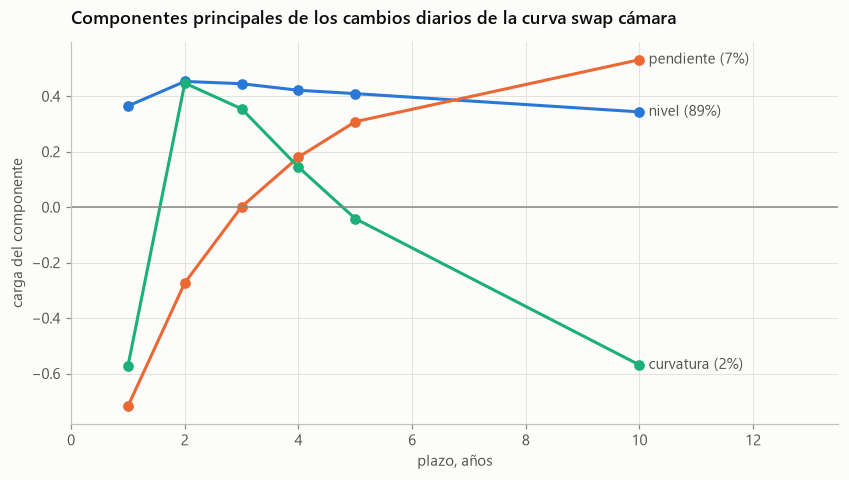

,sensibilidad paralela,exposición al nivel,exposición a la pendiente,desviación diaria,VaR 99% histórico
sin cobertura,-2.5000,-1.0340,-1.5970,17.4360,48.6940
DV01 con el swap a 10 años,0.0000,-0.1760,-0.2680,10.0880,28.4130
nivel y pendiente con 2 y 10 años,0.5100,-0.0000,-0.0000,10.2550,29.3570


In [43]:
plazos_pca = ["1", "2", "3", "4", "5", "10"]
cambios_pb = swap[plazos_pca].diff().dropna() * 100
valores_pca, vectores_pca = np.linalg.eigh(cambios_pb.cov().to_numpy())
orden_pca = np.argsort(valores_pca)[::-1]
valores_pca, vectores_pca = valores_pca[orden_pca], vectores_pca[:, orden_pca]
vectores_pca[:, 0] *= np.sign(vectores_pca[:, 0].sum())
vectores_pca[:, 1] *= np.sign(vectores_pca[-1, 1] - vectores_pca[0, 1])
vectores_pca[:, 2] *= np.sign(vectores_pca[3, 2])
print("Varianza explicada:", (valores_pca[:3] / valores_pca.sum()).round(3))

exposicion = np.array([0.0, 2.0, 0.0, 0.0, -6.0, 1.5])
u2, u10 = np.eye(6)[1], np.eye(6)[5]
dv01_hedge = exposicion + (-exposicion.sum()) * u10
nivel, pendiente = vectores_pca[:, 0], vectores_pca[:, 1]
sistema = np.array([[nivel @ u2, nivel @ u10], [pendiente @ u2, pendiente @ u10]])
h2, h10 = np.linalg.solve(sistema, -np.array([nivel @ exposicion, pendiente @ exposicion]))
pca_hedge = exposicion + h2 * u2 + h10 * u10
filas = {}
for nombre, vector in [("sin cobertura", exposicion), ("DV01 con el swap a 10 años", dv01_hedge), ("nivel y pendiente con 2 y 10 años", pca_hedge)]:
    pnl = cambios_pb.to_numpy() @ vector
    filas[nombre] = {"sensibilidad paralela": vector.sum(), "exposición al nivel": nivel @ vector, "exposición a la pendiente": pendiente @ vector,
                     "desviación diaria": pnl.std(), "VaR 99% histórico": -np.quantile(pnl, 0.01)}
print(f"Cobertura de dos factores: {h2:+.2f} millones por pb en 2 años y {h10:+.2f} en 10 años")

fig, ax = plt.subplots(figsize=(9, 4.5))
x_pl = [float(p) for p in plazos_pca]
for color, j, nombre in zip(COLORES, range(3), ("nivel", "pendiente", "curvatura")):
    ax.plot(x_pl, vectores_pca[:, j], color=color, linewidth=2, marker="o")
    ax.annotate(f"{nombre} ({valores_pca[j] / valores_pca.sum():.0%})", (10, vectores_pca[-1, j]), xytext=(6, 0), textcoords="offset points",
                va="center", color=TINTA_SECUNDARIA)
ax.axhline(0, color=TINTA_TENUE, linewidth=1)
ax.set_xlim(0, 13.5)
ax.set_xlabel("plazo, años")
ax.set_ylabel("carga del componente")
ax.set_title("Componentes principales de los cambios diarios de la curva swap cámara")
fig.savefig(FIGURAS / "pca_curva_swap.png", bbox_inches="tight")
plt.show()
pd.DataFrame(filas).T.round(3)

**Lectura.**

- **Nivel, pendiente y curvatura explican 89%, 7% y 2%** de la varianza de los cambios diarios de la curva swap.
- **Una sensibilidad paralela pequeña oculta mucho riesgo.** La cartera pierde solo 2,5 millones por punto base paralelo, pero tiene una desviación diaria de 17,4 millones, porque está larga en 5 años frente a los extremos.
- **Ambas coberturas bajan la desviación a unos 10 millones, y ninguna más.** La de nivel y pendiente casi no usa el swap a 2 años y no mejora a la de DV01: el riesgo que queda es la posición en 5 años frente a 2 y 10, una exposición a curvatura y a movimientos propios del plazo de 5 años que los extremos no cubren. Para eliminarla haría falta un instrumento a 5 años.

### Ejercicios resueltos

**Ejercicio 13.1. Resultado por tasas clave** *(ejercicio propio)*

Una cartera cambia de valor en −3.000, +1.000 y +4.000 por punto base de alza en las tasas a 2, 5 y 10 años. ¿Cuánto gana o pierde con un aplanamiento en que la tasa a 2 años sube 20 pb, la de 5 años sube 5 pb y la de 10 años baja 10 pb? ¿Y con un alza paralela de 10 pb?

In [44]:
krd = np.array([-3_000.0, 1_000.0, 4_000.0])
print(f"Aplanamiento: -3.000·20 + 1.000·5 + 4.000·(-10) = {krd @ np.array([20, 5, -10]):+,.0f}")
print(f"Respuesta: paralelo de +10 pb: {krd.sum() * 10:+,.0f}. La cartera parece casi inmune al nivel, pero pierde mucho con el aplanamiento.")

Aplanamiento: -3.000·20 + 1.000·5 + 4.000·(-10) = -95,000
Respuesta: paralelo de +10 pb: +20,000. La cartera parece casi inmune al nivel, pero pierde mucho con el aplanamiento.


**Ejercicio 13.2. Cubrir dos tasas clave con dos instrumentos** *(ejercicio propio)*

Una cartera tiene sensibilidades de −8.000 a 2 años y −15.000 a 10 años. Hay dos instrumentos: un swap A con sensibilidades de +4.000 a 2 años y +500 a 10 años, y un swap B con +300 y +6.000. ¿Cuántas unidades de cada uno neutralizan ambas tasas clave?

In [45]:
instrumentos = np.array([[4_000.0, 300.0], [500.0, 6_000.0]])
unidades = np.linalg.solve(instrumentos, np.array([8_000.0, 15_000.0]))
print(f"Respuesta: {unidades[0]:.3f} unidades de A y {unidades[1]:.3f} de B; sensibilidad final: {np.round(instrumentos @ unidades - np.array([8_000, 15_000]), 6) + 0}")

Respuesta: 1.824 unidades de A y 2.348 de B; sensibilidad final: [0. 0.]


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

La duración de tasa clave (key rate duration) se usa para:

- **A.** medir la sensibilidad de un bono o cartera a un cambio en el rendimiento de un vencimiento específico, capturando desplazamientos no paralelos de la curva.
- **B.** medir solo la sensibilidad a un desplazamiento paralelo.
- **C.** calcular la convexidad de un swap.
- **D.** valuar una opción sobre acciones.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Las duraciones de tasa clave (o parciales) descomponen el riesgo de tasa por punto de vencimiento en la curva. Revelan la exposición a empinamientos, aplanamientos o movimientos butterfly que una única duración efectiva — que supone un desplazamiento paralelo — pasaría por alto.

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad avanzada)*

Una cartera cambia de valor en −$2.000 por cada punto base que sube la tasa a 2 años, −$5.000 por la de 5 años y +$6.000 por la de 10 años. Si la curva se empina, con la tasa a 2 años bajando 10 pb, la de 5 años sin cambio y la de 10 años subiendo 10 pb, ¿cuánto cambia el valor?

- **A.** +$40.000
- **B.** −$80.000
- **C.** +$80.000
- **D.** −$40.000

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Se suman las contribuciones de cada plazo: (−2.000)(−10) + (−5.000)(0) + (6.000)(10) = 20.000 + 60.000 = +$80.000. Ante un alza paralela de 1 pb la cartera perdería 2.000 + 5.000 − 6.000 = $1.000, una exposición pequeña que oculta un riesgo grande a la pendiente.

</details>

### Trampas frecuentes

- Una cartera con DV01 cero puede tener mucho riesgo de pendiente.
- La suma de las duraciones de tasas clave es la duración ante un desplazamiento paralelo.
- Para neutralizar k factores de riesgo se necesitan al menos k instrumentos de cobertura.

## VRM-14. Árboles binomiales

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Un paso.** Una cartera con Δ acciones y una opción vendida es libre de riesgo si $\Delta = (f_u - f_d)/(S_u - S_d)$. De ahí la valoración neutral al riesgo: $f = e^{-r\Delta t}[pf_u + (1-p)f_d]$, con $p = (e^{r\Delta t} - d)/(u - d)$.
- **Cox, Ross y Rubinstein.** $u = e^{\sigma\sqrt{\Delta t}}$ y $d = 1/u$. Con más pasos, el precio converge a Black-Scholes, oscilando.
- **Opciones americanas.** En cada nodo se compara el valor de continuar con el de ejercer y se toma el mayor.
- **Otros subyacentes.** Con rendimiento q, $p = (e^{(r-q)\Delta t} - d)/(u - d)$: índices con dividendos, divisas (q es la tasa extranjera) y futuros (q = r).
- **Delta y otras griegas** se obtienen de los nodos del árbol.

### Análisis avanzado: el valor del ejercicio anticipado según plazo y moneyness

Con un árbol de 300 pasos, el mismo para ambas para que el error de discretización se cancele, se valoran puts americanas y europeas sobre el ETF IPSA, con la volatilidad de dos años y la TPM, para strikes de 80% a 120% del precio y plazos de 3 meses, 1 y 2 años. El premio por ejercicio anticipado se mide como porcentaje de la put europea.

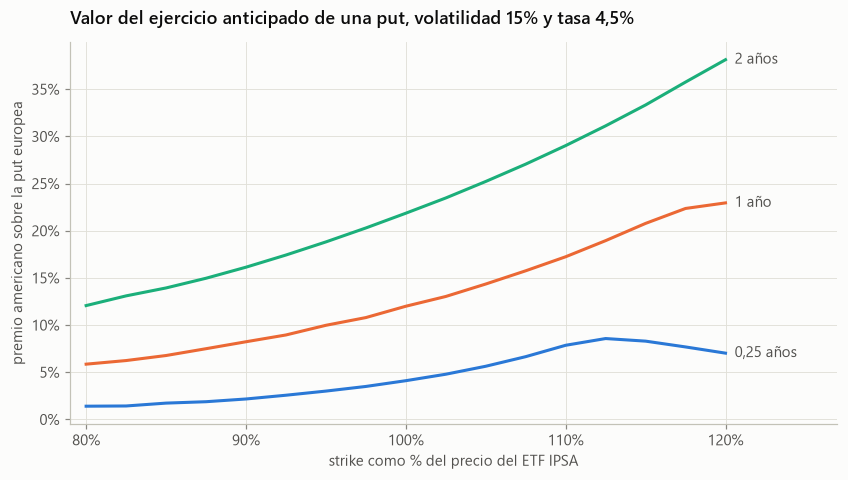

,"0,25 años",1 año,2 años
0.8000,1.4%,5.9%,12.1%
0.9000,2.2%,8.2%,16.1%
1.0000,4.1%,12.0%,21.9%
1.1000,7.9%,17.2%,29.0%
1.2000,7.0%,22.9%,38.1%


In [46]:
s_etf = float(precios["ETF IPSA"].iloc[-1])
vol_etf = float(np.log(precios["ETF IPSA"]).diff().iloc[-504:].std() * np.sqrt(252))
moneyness = np.round(np.arange(0.80, 1.201, 0.025), 3)
premios = {}
for plazo in (0.25, 1.0, 2.0):
    fila = []
    for m in moneyness:
        americana = frm.arbol_binomial(s_etf, m * s_etf, r_clp, vol_etf, plazo, 300, "put", americana=True)
        europea = frm.arbol_binomial(s_etf, m * s_etf, r_clp, vol_etf, plazo, 300, "put", americana=False)
        fila.append((americana - europea) / europea)
    premios[(f"{plazo:g} año" + ("" if plazo == 1 else "s")).replace(".", ",")] = fila
premios = pd.DataFrame(premios, index=moneyness)
fig, ax = plt.subplots(figsize=(9, 4.5))
for color, columna in zip(COLORES, premios.columns):
    ax.plot(premios.index, premios[columna], color=color, linewidth=2)
    ax.annotate(columna, (premios.index[-1], premios[columna].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center",
                color=TINTA_SECUNDARIA)
eje_porcentaje(ax, "x")
eje_porcentaje(ax)
ax.set_xlim(0.79, 1.27)
ax.set_xlabel("strike como % del precio del ETF IPSA")
ax.set_ylabel("premio americano sobre la put europea")
ax.set_title(f"Valor del ejercicio anticipado de una put, volatilidad {vol_etf:.0%} y tasa {r_clp:.1%}".replace(".", ","))
plt.show()
premios.iloc[::4].map("{:.1%}".format)

**Lectura.**

- **El ejercicio anticipado vale más en plazos largos y puts dentro del dinero.** A dos años y con strike de 120% del precio, la put americana vale 38% más que la europea; a tres meses y fuera del dinero, apenas 1%.
- **La razón es el interés sobre el strike.** Con una tasa de 4,5%, cobrar el strike antes vale mucho cuando falta mucho para el vencimiento.
- **A tres meses, el premio relativo baja en las puts muy dentro del dinero.** El premio absoluto se estabiliza en el interés del strike, mientras la put europea sigue creciendo.

### Ejercicios resueltos

**Ejercicio 14.1. Un paso y cartera réplica** *(banco de ejercicios de frm-prep)*

Una acción vale 100 y en un período sube a 120 o baja a 80. Con tasa de 0% y strike de 100, valora la call y encuentra la cartera que la replica.

In [47]:
s0, su, sd, k_ = 100, 120, 80, 100
fu, fd = max(su - k_, 0), max(sd - k_, 0)
p_ = (1 - 0.8) / (1.2 - 0.8)
delta_ = (fu - fd) / (su - sd)
bono = fd - delta_ * sd
print(f"p = (1 - 0,8)/(1,2 - 0,8) = {p_:.2f}; call = {p_} × 20 + {1 - p_} × 0 = {p_ * fu + (1 - p_) * fd:.2f}")
print(f"Respuesta: la réplica compra Δ = {delta_:.2f} acciones y pide prestados {-bono:.0f}: cuesta {delta_ * s0 + bono:.2f}, lo mismo que la call.")

p = (1 - 0,8)/(1,2 - 0,8) = 0.50; call = 0.5 × 20 + 0.5 × 0 = 10.00
Respuesta: la réplica compra Δ = 0.50 acciones y pide prestados 40: cuesta 10.00, lo mismo que la call.


**Ejercicio 14.2. Put americana de dos pasos** *(ejercicio propio)*

Una acción vale 50; en cada paso sube 20% o baja 20%, y la tasa es 5% por paso, con capitalización discreta. Valora una put europea y una americana con strike 52 a dos pasos.

In [48]:
u_, d_, r_ = 1.2, 0.8, 0.05
p_ = (1 + r_ - d_) / (u_ - d_)
precios_t = {2: np.array([50 * u_**2, 50 * u_ * d_, 50 * d_**2]), 1: np.array([50 * u_, 50 * d_]), 0: np.array([50.0])}
europea = np.maximum(52 - precios_t[2], 0)
americana = europea.copy()
for paso in (1, 0):
    europea = (p_ * europea[:-1] + (1 - p_) * europea[1:]) / (1 + r_)
    americana = np.maximum((p_ * americana[:-1] + (1 - p_) * americana[1:]) / (1 + r_), 52 - precios_t[paso])
print(f"p = (1,05 - 0,8)/(1,2 - 0,8) = {p_:.4f}")
print(f"Respuesta: put europea {europea[0]:.4f}; americana {americana[0]:.4f}. En el nodo de 40 conviene ejercer: 12 > valor de continuar.")

p = (1,05 - 0,8)/(1,2 - 0,8) = 0.6250
Respuesta: put europea 4.2517; americana 5.1361. En el nodo de 40 conviene ejercer: 12 > valor de continuar.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Una acción vale \$50; en cada período sube por 1.2 o baja por 0.8. Con strike \$50 y tasa 0%, el valor de una put europea de dos pasos es más cercano a:

- **A.** $5.50
- **B.** $4.50
- **C.** $2.00
- **D.** $18.00

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** $p = \dfrac{1-0.8}{1.2-0.8} = 0.5$. Nodos terminales: \$72 $\to 0$; \$48 $\to 2$; \$32 $\to 18$. $P = 2p(1-p)(2) + (1-p)^2(18) = 1.0 + 4.5 = \$5.50$.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Las opciones put americanas sobre acciones que no pagan dividendos pueden ejercerse anticipadamente de forma óptima porque:

- **A.** La put tiene delta negativo
- **B.** La paridad put-call exige el ejercicio anticipado
- **C.** La acción subyacente puede quedar sin valor
- **D.** Cuando una put está muy ITM, el beneficio del interés sobre el valor intrínseco puede superar el valor temporal restante

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Para una put americana muy ITM: mantenerla significa renunciar al interés libre de riesgo sobre el valor intrínseco (K − S). Si S se acerca a 0, el valor intrínseco de la put ≈ K, y mantenerla más tiempo no gana beneficio adicional mientras renuncia al interés sobre K. El ejercicio anticipado es óptimo cuando ese interés supera el valor temporal restante.

</details>

### Trampas frecuentes

- La probabilidad neutral al riesgo no es la probabilidad real de que suba la acción.
- Para divisas, la probabilidad usa r − q, con q la tasa extranjera; para futuros, q = r.
- En una americana, el ejercicio se evalúa en cada nodo, no solo al vencimiento.

## VRM-15. El modelo Black-Scholes-Merton

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Supuestos.** El precio sigue un movimiento browniano geométrico con volatilidad constante, sin costos ni restricciones a la venta corta, tasa constante y negociación continua.
- **Lognormalidad.** $\ln S_T \sim N\left(\ln S_0 + (\mu - \sigma^2/2)T, \sigma^2T\right)$. La probabilidad real de terminar sobre K usa μ; la neutral al riesgo, $N(d_2)$, usa r.
- **Fórmulas.** $c = S_0e^{-qT}N(d_1) - Ke^{-rT}N(d_2)$ y $p = Ke^{-rT}N(-d_2) - S_0e^{-qT}N(-d_1)$, con $d_1 = \frac{\ln(S_0/K) + (r - q + \sigma^2/2)T}{\sigma\sqrt T}$ y $d_2 = d_1 - \sigma\sqrt T$.
- **Variantes.** Divisas (Garman-Kohlhagen, con q igual a la tasa extranjera), futuros (Black, con q = r) y dividendos discretos (se resta su valor presente).
- **Volatilidad implícita.** La que iguala el precio de mercado; varía con el strike (sonrisa o sesgo) y con el plazo, lo que revela que el mercado no cree en la lognormal.

### Análisis avanzado: ¿acierta la lognormal con las probabilidades del dólar?

Cada fin de mes desde 2005, con la volatilidad del año anterior y sin tendencia, la lognormal da la probabilidad de que el dólar suba o baje más de 10% en los 12 meses siguientes. Se compara con lo que efectivamente pasó, y se mide cuántos cambios de 12 meses superaron dos desviaciones estándar.

In [49]:
log_dolar = np.log(dolar)
r_diaria = log_dolar.diff()
volatilidad_previa = (r_diaria.rolling(252).std() * np.sqrt(252)).resample("ME").last()
nivel_mensual = log_dolar.resample("ME").last()
cambio_12m = nivel_mensual.shift(-12) - nivel_mensual
base = pd.concat({"sigma": volatilidad_previa, "cambio": cambio_12m}, axis=1).loc["2005":].dropna()
base["P(sube más de 10%)"] = stats.norm.sf((np.log(1.10) + base["sigma"] ** 2 / 2) / base["sigma"])
base["P(baja más de 10%)"] = stats.norm.cdf((np.log(0.90) + base["sigma"] ** 2 / 2) / base["sigma"])
base["subió más de 10%"] = base["cambio"] > np.log(1.10)
base["bajó más de 10%"] = base["cambio"] < np.log(0.90)
base["cambio estandarizado"] = base["cambio"] / base["sigma"]
filas = {}
for evento, resultado in [("P(sube más de 10%)", "subió más de 10%"), ("P(baja más de 10%)", "bajó más de 10%")]:
    brier = np.mean((base[evento] - base[resultado]) ** 2)
    brier_ingenuo = np.mean((base[resultado].mean() - base[resultado]) ** 2)
    filas[evento] = {"probabilidad media del modelo": base[evento].mean(), "frecuencia observada": base[resultado].mean(),
                     "Brier del modelo": brier, "Brier de la frecuencia histórica": brier_ingenuo}
print(f"{len(base)} meses. Cambios de 12 meses que superaron dos desviaciones: {(base['cambio estandarizado'].abs() > 2).mean():.1%},"
      f" frente a 4,6% con la normal. Curtosis de los cambios estandarizados: {stats.kurtosis(base['cambio estandarizado'], fisher=False):.2f}")
grupos = pd.qcut(base["P(sube más de 10%)"], 3, labels=["tercio bajo", "tercio medio", "tercio alto"])
print("\nCalibración por tercios de la probabilidad de subir más de 10%:")
print(base.groupby(grupos, observed=True)[["P(sube más de 10%)", "subió más de 10%"]].mean().round(3).to_string())
pd.DataFrame(filas).T.round(4)

249 meses. Cambios de 12 meses que superaron dos desviaciones: 11.2%, frente a 4,6% con la normal. Curtosis de los cambios estandarizados: 4.43

Calibración por tercios de la probabilidad de subir más de 10%:
                    P(sube más de 10%)  subió más de 10%
P(sube más de 10%)                                      
tercio bajo                     0.0910            0.4460
tercio medio                    0.1570            0.1930
tercio alto                     0.2230            0.1570


,probabilidad media del modelo,frecuencia observada,Brier del modelo,Brier de la frecuencia histórica
P(sube más de 10%),0.1572,0.2651,0.2220,0.1948
P(baja más de 10%),0.1614,0.1044,0.0954,0.0935


**Lectura.**

- **La lognormal subestima las colas.** El 11,2% de los cambios de 12 meses del dólar superó dos desviaciones, frente a 4,6% con la normal, y la curtosis de los cambios estandarizados es 4,4.
- **Sus probabilidades no sirven para pronosticar.** Para una subida de más de 10%, el modelo daba en promedio 15,7% y ocurrió en 26,5% de los meses. Su puntaje de Brier, 0,222, es peor que usar la frecuencia histórica, 0,195. La calibración está al revés: cuando el modelo daba la menor probabilidad, 9%, el dólar subió más de 10% en 45% de los casos, porque los períodos de volatilidad baja precedieron a grandes depreciaciones.
- **Black-Scholes sirve para valorar,** con una volatilidad implícita que el mercado ajusta, no para estimar probabilidades reales.

### Ejercicios resueltos

**Ejercicio 15.1. d₁, d₂ y el precio de una call** *(banco de ejercicios de frm-prep)*

Calcula d₁ y d₂ para S = K = 50, r = 5%, σ = 20% y T = 1. Luego calcula el precio de la call.

In [50]:
d1 = (np.log(50 / 50) + (0.05 + 0.2**2 / 2) * 1) / 0.2
d2 = d1 - 0.2
precio_c = 50 * stats.norm.cdf(d1) - 50 * np.exp(-0.05) * stats.norm.cdf(d2)
print(f"d1 = (0 + 0,07) / 0,2 = {d1:.2f}; d2 = {d2:.2f}; N(d1) = {stats.norm.cdf(d1):.4f}; N(d2) = {stats.norm.cdf(d2):.4f}")
print(f"Respuesta: c = 50 × {stats.norm.cdf(d1):.4f} - 50 × e^(-0,05) × {stats.norm.cdf(d2):.4f} = {precio_c:.2f}")

d1 = (0 + 0,07) / 0,2 = 0.35; d2 = 0.15; N(d1) = 0.6368; N(d2) = 0.5596
Respuesta: c = 50 × 0.6368 - 50 × e^(-0,05) × 0.5596 = 5.23


**Ejercicio 15.2. Volatilidad implícita, divisas y futuros** *(ejercicio propio)*

Una call con S = K = 50, r = 5% y T = 1 cotiza a 7,00: ¿qué volatilidad implica? Luego valora una call a 6 meses sobre el dólar con strike igual al spot (Garman-Kohlhagen) y una call a 6 meses sobre un futuro de cobre de 4,50 dólares la libra con strike 4,50, volatilidad de 25% y tasa de 4,5% (Black).

In [51]:
iv = fa.volatilidad_implicita(7.00, 50, 50, 0.05, 1.0)
print(f"Volatilidad implícita: {iv:.2%} (el precio de 7,00 supera los 5,23 que corresponden a 20%)")
print(f"Call sobre el dólar: {frm.black_scholes(spot, spot, r_clp, vol_usd, 0.5, q=r_usd):.2f} pesos por dólar")
print(f"Respuesta: call sobre el futuro de cobre: {fa.black_76(4.50, 4.50, 0.045, 0.25, 0.5):.4f} dólares por libra.")

Volatilidad implícita: 29.39% (el precio de 7,00 supera los 5,23 que corresponden a 20%)
Call sobre el dólar: 28.29 pesos por dólar
Respuesta: call sobre el futuro de cobre: 0.3099 dólares por libra.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

El modelo BSM supone que los precios de las acciones siguen un movimiento browniano geométrico (MBG). Una propiedad clave del MBG es que:

- **A.** Los retornos logarítmicos están normalmente distribuidos con media (μ − σ²/2)T y varianza σ²T
- **B.** La volatilidad es estocástica
- **C.** Los retornos tienen reversión a la media
- **D.** Los precios de las acciones pueden ser negativos

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** MBG: dS = μS dt + σS dW. Aplicando el lema de Itô: d(ln S) = (μ − σ²/2)dt + σdW. Así, ln(S_T/S₀) ~ N[(μ−σ²/2)T, σ²T]. Los precios de las acciones se distribuyen de forma lognormal (siempre positivos) y los retornos logarítmicos son normales.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

La volatilidad implícita es:

- **A.** la volatilidad que, al ingresarse en un modelo de valuación de opciones, reproduce el precio de mercado observado de la opción.
- **B.** siempre igual a la volatilidad realizada.
- **C.** el delta de la opción.
- **D.** la volatilidad histórica del subyacente.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** La volatilidad implícita se despeja del precio de mercado usando un modelo como Black-Scholes. Refleja la visión prospectiva del mercado sobre la volatilidad y suele diferir entre strikes y vencimientos (la sonrisa/sesgo y la estructura temporal).

</details>

### Trampas frecuentes

- N(d₂) es la probabilidad neutral al riesgo de ejercer; la real usa μ en vez de r.
- La volatilidad implícita no es un pronóstico puro: incluye una prima por riesgo de volatilidad.
- Con dividendos, el precio de la acción se reemplaza por S·e^(−qT) o por S menos el valor presente de los dividendos.

## VRM-16. Las griegas

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Delta.** $\partial V/\partial S$: $e^{-qT}N(d_1)$ en una call y $e^{-qT}(N(d_1) - 1)$ en una put. Se neutraliza con el subyacente.
- **Gamma.** $\partial^2V/\partial S^2$, igual para call y put. Es máxima en el dinero y cerca del vencimiento. Solo se neutraliza con otras opciones.
- **Vega, theta y rho.** Sensibilidad a la volatilidad, al paso del tiempo y a la tasa. El subyacente no tiene vega ni gamma.
- **Relación de Black-Scholes.** $\Theta + (r - q)S\Delta + \frac{1}{2}\sigma^2S^2\Gamma = rV$: una cartera neutral en delta con gamma positiva pierde por theta.
- **Resultado de una cartera cubierta.** $\Delta V \approx \Delta\cdot\Delta S + \frac{1}{2}\Gamma\Delta S^2 + \nu\,\Delta\sigma + \Theta\,\Delta t$. Una cartera neutral en delta gana o pierde según la gamma y la volatilidad realizada.
- **Seguro de cartera.** Replicar una put con el subyacente y efectivo exige vender cuando el mercado cae, lo que amplifica las caídas, como en 1987.

### Análisis avanzado: cobertura delta frente a delta-gamma con trayectorias reales

Un banco vende calls a un mes en el dinero sobre USD 10 millones, valoradas con la volatilidad del año anterior. Desde 2010, en ventanas sucesivas de 21 días hábiles, se compara el resultado sin cubrir, con cobertura delta diaria y con cobertura delta-gamma diaria usando una call a dos meses con el mismo strike. Como las tasas en pesos y en dólares son parecidas, se omiten los intereses.

198 ventanas de un mes desde 01-2010. Resultado como fracción de la prima:


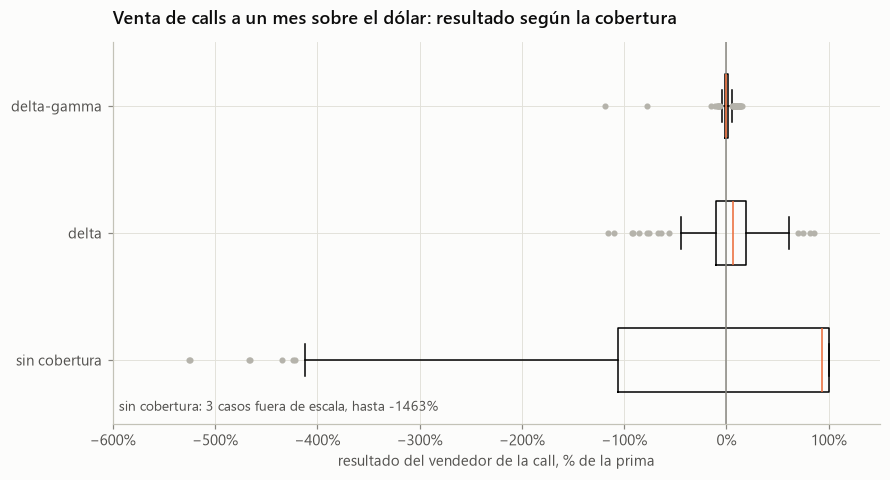

,media,desviación,percentil 5%,peor
sin cobertura,-26%,+206%,-414%,-1463%
delta,+5%,+31%,-46%,-116%
delta-gamma,-0%,+11%,-5%,-119%


In [52]:
serie = dolar.loc["2009":]
vol_previa = np.log(dolar).diff().rolling(252).std() * np.sqrt(252)
nominal_g, dias = 10.0, 21
resultados = []
for inicio in range(252, len(serie) - dias, dias):
    trayectoria = serie.iloc[inicio:inicio + dias + 1].to_numpy()
    sigma_v = float(vol_previa.loc[serie.index[inicio]])
    k_g = trayectoria[0]
    prima = frm.black_scholes(trayectoria[0], k_g, 0.0, sigma_v, dias / 252)
    caja_d, unidades_d = prima, 0.0
    caja_g, unidades_g, opciones_g = prima, 0.0, 0.0
    for i in range(dias):
        s_i, t_corta, t_larga = trayectoria[i], (dias - i) / 252, (2 * dias - i) / 252
        g_corta = frm.griegas(s_i, k_g, 0.0, sigma_v, t_corta)
        g_larga = frm.griegas(s_i, k_g, 0.0, sigma_v, t_larga)
        nueva_d = g_corta["delta"]
        caja_d -= (nueva_d - unidades_d) * s_i
        unidades_d = nueva_d
        nuevas_op = g_corta["gamma"] / g_larga["gamma"]
        precio_larga = frm.black_scholes(s_i, k_g, 0.0, sigma_v, t_larga)
        caja_g -= (nuevas_op - opciones_g) * precio_larga
        opciones_g = nuevas_op
        nueva_g = g_corta["delta"] - opciones_g * g_larga["delta"]
        caja_g -= (nueva_g - unidades_g) * s_i
        unidades_g = nueva_g
    s_fin = trayectoria[-1]
    pago = max(s_fin - k_g, 0)
    larga_fin = frm.black_scholes(s_fin, k_g, 0.0, sigma_v, dias / 252)
    resultados.append({"fecha": serie.index[inicio], "prima": prima,
                       "sin cobertura": (prima - pago) / prima,
                       "delta": (caja_d + unidades_d * s_fin - pago) / prima,
                       "delta-gamma": (caja_g + unidades_g * s_fin + opciones_g * larga_fin - pago) / prima})
cobertura = pd.DataFrame(resultados).set_index("fecha")
estrategias = ["sin cobertura", "delta", "delta-gamma"]
resumen_cob = pd.DataFrame({"media": cobertura[estrategias].mean(), "desviación": cobertura[estrategias].std(),
                            "percentil 5%": cobertura[estrategias].quantile(0.05), "peor": cobertura[estrategias].min()})
print(f"{len(cobertura)} ventanas de un mes desde {cobertura.index[0]:%m-%Y}. Resultado como fracción de la prima:")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([cobertura[e] for e in estrategias], tick_labels=estrategias, orientation="horizontal", widths=0.5,
           medianprops={"color": COLORES[1]}, flierprops={"markersize": 3, "markerfacecolor": NEUTRO, "markeredgecolor": NEUTRO})
ax.axvline(0, color=TINTA_TENUE, linewidth=1)
ax.set_xlim(-6, 1.5)
ax.annotate(f"sin cobertura: {int((cobertura['sin cobertura'] < -6).sum())} casos fuera de escala, hasta {cobertura['sin cobertura'].min():.0%}",
            (-6, 0.6), xytext=(4, 0), textcoords="offset points", color=TINTA_SECUNDARIA, fontsize=9)
eje_porcentaje(ax, "x")
ax.set_xlabel("resultado del vendedor de la call, % de la prima")
ax.set_title("Venta de calls a un mes sobre el dólar: resultado según la cobertura")
fig.savefig(FIGURAS / "cobertura_griegas.png", bbox_inches="tight")
plt.show()
resumen_cob.map("{:+.0%}".format)

**Lectura.**

- **Sin cobertura, vender calls es una apuesta:** en promedio pierde 26% de la prima, con una desviación de 206% y un peor caso de −1.463%.
- **La cobertura delta baja la desviación a 31% de la prima, y la delta-gamma, a 11%.** El error que deja la delta viene de la gamma: los movimientos del dólar entre un ajuste y el siguiente.
- **Ninguna cobertura elimina los peores casos, cercanos a −120% de la prima.** Son meses con una volatilidad realizada muy superior a la usada para valorar: un riesgo de vega que ni la delta ni la gamma cubren.
- **El resultado promedio de la cobertura delta, +5%, sugiere que la volatilidad usada para valorar fue algo mayor que la realizada:** el vendedor cobró, en promedio, una prima de volatilidad.

### Ejercicios resueltos

**Ejercicio 16.1. Cobertura delta** *(banco de ejercicios de frm-prep)*

Un trader vendió 100 calls, cada una sobre una acción, con delta de 0,6. ¿Cuántas acciones debe comprar para quedar neutral en delta? ¿Y si cada contrato cubre 100 acciones?

In [53]:
print(f"Delta de la posición = -100 × 0,6 = {-100 * 0.6:.0f}: comprar 60 acciones")
print(f"Respuesta: con contratos de 100 acciones, comprar 100 × 100 × 0,6 = {100 * 100 * 0.6:,.0f} acciones.")

Delta de la posición = -100 × 0,6 = -60: comprar 60 acciones
Respuesta: con contratos de 100 acciones, comprar 100 × 100 × 0,6 = 6,000 acciones.


**Ejercicio 16.2. Neutralidad en gamma y vega** *(ejercicio propio)*

Una cartera de opciones tiene delta 0, gamma −5.000 y vega −8.000. Hay dos opciones negociables: la primera con delta 0,6, gamma 0,5 y vega 2,0; la segunda con delta 0,5, gamma 0,8 y vega 1,2. ¿Cuántas de cada una y cuántas acciones hacen la cartera neutral en delta, gamma y vega?

In [54]:
instrumentos_g = pd.DataFrame({"delta": [0.6, 0.5], "gamma": [0.5, 0.8], "vega": [2.0, 1.2]}, index=["opción 1", "opción 2"])
cantidades = fa.neutralizar_griegas({"delta": 0.0, "gamma": -5_000.0, "vega": -8_000.0}, instrumentos_g)
print(cantidades.round(2).to_string())
print("Respuesta: comprar las dos opciones anula gamma y vega, y vender acciones devuelve la delta a cero, porque las opciones compradas tienen delta positiva.")

opción 1        400.0000
opción 2      6,000.0000
subyacente   -3,240.0000
Respuesta: comprar las dos opciones anula gamma y vega, y vender acciones devuelve la delta a cero, porque las opciones compradas tienen delta positiva.


**Ejercicio 16.3. Atribución de Taylor frente a revaluación completa** *(ejercicio propio)*

Una call con S = K = 100, r = 5%, σ = 20% y T = 0,5. En una semana, S sube a 105 y la volatilidad a 22%. Compara el cambio de valor estimado con delta, gamma, vega y theta con el cambio exacto, y verifica la relación de Black-Scholes entre las griegas.

In [55]:
g0 = frm.griegas(100, 100, 0.05, 0.20, 0.5)
partes = fa.atribucion_taylor(g0["delta"], g0["gamma"], g0["vega"], g0["theta"], 5, 0.02, 1 / 52)
exacto = frm.black_scholes(105, 100, 0.05, 0.22, 0.5 - 1 / 52) - frm.black_scholes(100, 100, 0.05, 0.20, 0.5)
print({k: round(v, 4) for k, v in partes.items()})
print(f"Cambio exacto {exacto:.4f}; error de la aproximación {partes['total'] - exacto:+.4f}")
c0 = frm.black_scholes(100, 100, 0.05, 0.20, 0.5)
print(f"Respuesta: Θ + rSΔ + ½σ²S²Γ = {g0['theta'] + 0.05 * 100 * g0['delta'] + 0.5 * 0.04 * 100**2 * g0['gamma']:.4f} = r·c = {0.05 * c0:.4f}")

{'delta': 2.9887, 'gamma': 0.342, 'vega': 0.5472, 'theta': -0.1561, 'total': 3.7218}
Cambio exacto 3.6456; error de la aproximación +0.0762
Respuesta: Θ + rSΔ + ½σ²S²Γ = 0.3444 = r·c = 0.3444


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Un trader está corto en 100 contratos de opción call (cada uno sobre 100 acciones) con un delta de 0.6. ¿Cuántas acciones debe comprar para cubrir el delta de la posición?

- **A.** 60 acciones
- **B.** 600 acciones
- **C.** 10,000 acciones
- **D.** 6,000 acciones

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Delta total de las opciones = 100 contratos × 100 acciones × 0.6 = 6,000. Estar corto en calls da delta negativo, así que se compran 6,000 acciones para neutralizar.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

Un gestor de una cartera de opciones quiere lograr simultáneamente neutralidad delta y neutralidad gamma. ¿Por qué no puede lograrse neutralidad delta-gamma usando únicamente acciones como instrumento de cobertura?

- **A.** Porque las acciones tienen gamma = 0, por lo que no afectan el gamma de la cartera al agregarlas; se necesita otra opción para ajustar el gamma.
- **B.** Porque las acciones tienen un vega distinto de cero, que interfiere con la cobertura gamma.
- **C.** Porque las acciones tienen delta = 0, lo que las hace inútiles para ajustar el delta de la cartera.
- **D.** Porque el theta de las acciones es positivo, compensando el gamma de las opciones.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Las acciones tienen **delta = 1** y **gamma = 0**. Cuando añades acciones a una cartera: el delta de la cartera cambia (útil para neutralidad delta), pero el gamma de la cartera no cambia en absoluto (las acciones no contribuyen gamma). Para ajustar el gamma, necesitas agregar una **opción** (cualquier instrumento con gamma ≠ 0). El proceso correcto es: (1) Comprar/vender opciones para hacer el gamma = 0 (esto cambia el delta), (2) Luego comprar/vender acciones para restaurar delta = 0 (esto no afecta el gamma). La opción B es incorrecta — el vega de las acciones es 0. La opción C es incorrecta — las acciones tienen delta = +1 (no 0). La opción D es incorrecta — el theta de acciones es ≈ 0, no positivo.

</details>

### Trampas frecuentes

- El subyacente no tiene gamma ni vega: para neutralizarlas se necesitan otras opciones.
- Una cartera neutral en delta con gamma positiva gana con movimientos grandes y pierde por theta si el precio no se mueve.
- Vega y rho suelen expresarse por punto porcentual; revisa las unidades antes de multiplicar.

## Resumen del libro

- **Las medidas de riesgo dependen de las colas.** El ES y las medidas espectrales miran más allá del VaR, y la no linealidad de las opciones exige revaluar, no solo multiplicar por la delta.
- **La volatilidad y las PD cambian con el tiempo.** El GARCH y las PD puntuales capturan el ciclo; las calificaciones de agencias y las volatilidades de largo plazo lo suavizan.
- **El capital depende de supuestos frágiles:** la correlación en Vasicek, la cola de la severidad operacional y la plausibilidad de un escenario de estrés.
- **La curva de tasas tiene varias dimensiones.** La cobertura por DV01 protege solo del nivel; la pendiente y la curvatura exigen coberturas de varios factores.
- **Las griegas explican el resultado de una cartera de opciones,** y la cobertura delta-gamma reduce el error que deja la delta cuando los precios saltan.